<a href="https://colab.research.google.com/github/Jeeban76/QRNG-testing/blob/main/wban.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from pathlib import Path
import os
import sys
import zipfile
import requests
import pandas as pd
import numpy as np
from tqdm.auto import tqdm

PROJECT_DIR = Path("/content/pamap2_research")
DOWNLOAD_DIR = PROJECT_DIR / "downloads"
RAW_DIR = PROJECT_DIR / "raw_data"
RESULTS_DIR = PROJECT_DIR / "results"

for folder in [DOWNLOAD_DIR, RAW_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Directories created successfully.")

Project directory: /content/pamap2_research
Python version: 3.13.16
Pandas version: 2.2.3
NumPy version: 2.1.3
Directories created successfully.


In [4]:
# STEP 2: Locate the uploaded PAMAP2 dataset

from pathlib import Path

PROJECT_DIR = Path("/content/pamap2_research")

print("Project directory:", PROJECT_DIR)

if not PROJECT_DIR.exists():
    raise FileNotFoundError("Project directory does not exist.")

# Find PAMAP2 data files
dat_files = sorted(PROJECT_DIR.rglob("*.dat"))

print("\nNumber of .dat files found:", len(dat_files))

for file in dat_files:
    print(file)

# Save the paths for our next research steps
DATA_FILES = dat_files

if DATA_FILES:
    print("\nSUCCESS: PAMAP2 data files located.")
else:
    print("\nNo .dat files found inside the project directory.")
    print("The dataset may be elsewhere or still inside a ZIP file.")

Project directory: /content/pamap2_research

Number of .dat files found: 0

No .dat files found inside the project directory.
The dataset may be elsewhere or still inside a ZIP file.


In [5]:
# STEP 1: Check the raw dataset directory

print("Raw dataset directory:", RAW_DIR)

if not RAW_DIR.exists():
    raise FileNotFoundError(f"Directory not found: {RAW_DIR}")

dat_files = sorted(RAW_DIR.rglob("*.dat"))

print("\nNumber of .dat files found:", len(dat_files))

for file in dat_files:
    print(
        f"{file.name} | "
        f"{file.stat().st_size / (1024**2):.2f} MB"
    )

if dat_files:
    print("\nDataset files found. Ready for raw-data inspection.")
else:
    print("\nNo .dat files found in RAW_DIR.")
    print("Place the extracted PAMAP2 dataset inside this directory.")


Raw dataset directory: /content/pamap2_research/raw_data

Number of .dat files found: 0

No .dat files found in RAW_DIR.
Place the extracted PAMAP2 dataset inside this directory.


In [6]:
# STEP 1: Download and extract the FORTH-TRACE dataset

import requests
import zipfile
from pathlib import Path
from tqdm.auto import tqdm

DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)
RAW_DIR.mkdir(parents=True, exist_ok=True)

ZIP_PATH = DOWNLOAD_DIR / "FORTH_TRACE_DATASET.zip"

DATASET_URL = (
    "https://zenodo.org/records/841301/files/"
    "FORTH_TRACE_DATASET.zip?download=1"
)

# Download directly into Colab
if not ZIP_PATH.exists():
    response = requests.get(
        DATASET_URL,
        stream=True,
        timeout=60
    )
    response.raise_for_status()

    total_size = int(response.headers.get("content-length", 0))

    with open(ZIP_PATH, "wb") as f:
        with tqdm(
            total=total_size if total_size else None,
            unit="B",
            unit_scale=True,
            desc="Downloading FORTH-TRACE"
        ) as progress:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
                    progress.update(len(chunk))

    response.close()

print("Dataset ZIP:", ZIP_PATH)
print(f"ZIP size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")

# Extract into the existing raw_data directory
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    archive.extractall(RAW_DIR)

print("Extraction completed.")
print("Raw dataset directory:", RAW_DIR)

# Locate the extracted CSV files
csv_files = sorted(RAW_DIR.rglob("*.csv"))

print("\nCSV files found:", len(csv_files))

for file in csv_files[:15]:
    print(file.relative_to(RAW_DIR))

if not csv_files:
    raise FileNotFoundError(
        "No CSV files found after extraction. "
        "Inspect the archive contents before proceeding."
    )

print("\nSTEP 1 STATUS: Dataset downloaded and located.")

Dataset ZIP: /content/pamap2_research/downloads/FORTH_TRACE_DATASET.zip
ZIP size: 105.44 MB
Extraction completed.
Raw dataset directory: /content/pamap2_research/raw_data

CSV files found: 75
FORTH_TRACE_DATASET-master/part0/part0dev1.csv
FORTH_TRACE_DATASET-master/part0/part0dev2.csv
FORTH_TRACE_DATASET-master/part0/part0dev3.csv
FORTH_TRACE_DATASET-master/part0/part0dev4.csv
FORTH_TRACE_DATASET-master/part0/part0dev5.csv
FORTH_TRACE_DATASET-master/part1/part1dev1.csv
FORTH_TRACE_DATASET-master/part1/part1dev2.csv
FORTH_TRACE_DATASET-master/part1/part1dev3.csv
FORTH_TRACE_DATASET-master/part1/part1dev4.csv
FORTH_TRACE_DATASET-master/part1/part1dev5.csv
FORTH_TRACE_DATASET-master/part10/part10dev1.csv
FORTH_TRACE_DATASET-master/part10/part10dev2.csv
FORTH_TRACE_DATASET-master/part10/part10dev3.csv
FORTH_TRACE_DATASET-master/part10/part10dev4.csv
FORTH_TRACE_DATASET-master/part10/part10dev5.csv

STEP 1 STATUS: Dataset downloaded and located.


In [7]:
# STEP 1: Inspect FORTH-TRACE raw dataset structure

from pathlib import Path
import pandas as pd

DATASET_DIR = RAW_DIR / "FORTH_TRACE_DATASET-master"
csv_files = sorted(DATASET_DIR.rglob("*.csv"))

print("=" * 60)
print("STEP 1: RAW DATASET INSPECTION")
print("=" * 60)

print("Dataset directory:", DATASET_DIR)
print("Total CSV files:", len(csv_files))

# Inspect the first CSV file
sample_file = csv_files[0]
sample_df = pd.read_csv(sample_file)

print("\nSample file:", sample_file.name)
print("Rows:", sample_df.shape[0])
print("Columns:", sample_df.shape[1])

print("\nColumn names:")
print(sample_df.columns.tolist())

print("\nFirst five rows:")
display(sample_df.head())

print("\nData types:")
display(sample_df.dtypes.to_frame("Data type"))

print("\nMissing values per column:")
display(
    sample_df.isnull()
    .sum()
    .to_frame("Missing values")
    .sort_values("Missing values", ascending=False)
)

print("\nDescriptive statistics:")
display(sample_df.describe(include="all").T)

# Check whether the other files have the same column structure
print("\nChecking column consistency across all CSV files...")

reference_columns = list(sample_df.columns)
inconsistent_files = []

for file in csv_files:
    columns = list(pd.read_csv(file, nrows=0).columns)
    if columns != reference_columns:
        inconsistent_files.append(file.name)

print("Files with different column structures:", len(inconsistent_files))

for name in inconsistent_files[:20]:
    print(name)

print("\nSTEP 1 STATUS: Initial raw-data inspection completed.")

STEP 1: RAW DATASET INSPECTION
Dataset directory: /content/pamap2_research/raw_data/FORTH_TRACE_DATASET-master
Total CSV files: 75

Sample file: part0dev1.csv
Rows: 53119
Columns: 12

Column names:
['1', '-1.865', '9.389', '2.5812', '-1.1418', '-1.1856', '0.84998', '-0.34476', '0.59839', '1.0134', '505.89', '1.1']

First five rows:


,1,-1.865,9.389,2.5812,-1.1418,-1.1856,0.84998,-0.34476,0.59839,1.0134,505.89,1.1
0,1,-1.7963,9.3742,2.4460,-1.56180,-0.66165,0.59730,-0.34274,0.57631,1.0000,525.42,1
1,1,-1.8696,9.3000,2.3514,-1.18770,-1.28410,0.14212,-0.34476,0.59639,1.0156,544.95,1
2,1,-1.7961,9.3624,2.4584,-0.58399,-2.03340,0.42912,-0.32863,0.62249,1.0156,564.48,1
3,1,-1.6768,9.3506,2.4685,-0.37050,-1.36470,0.37194,-0.33669,0.62048,1.0245,584.01,1
4,1,-1.6656,9.3378,2.4319,-0.79053,0.17793,0.38763,-0.32661,0.60442,1.0200,603.55,1



Data types:


,Data type
1,int64
-1.865,float64
9.389,float64
2.5812,float64
-1.1418,float64
-1.1856,float64
0.84998,float64
-0.34476,float64
0.59839,float64
1.0134,float64



Missing values per column:


,Missing values
1,0
-1.865,0
9.389,0
2.5812,0
-1.1418,0
-1.1856,0
0.84998,0
-0.34476,0
0.59839,0
1.0134,0



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
1,53119.0,1.000000,0.000000,1.00000,1.00000,1.000000,1.00000,1.000000e+00
-1.865,53119.0,-2.290077,0.946797,-9.28770,-2.76540,-2.326000,-1.93760,2.802600e+00
9.389,53119.0,7.707861,3.070227,0.17118,6.90530,9.074700,9.38650,1.715200e+01
2.5812,53119.0,4.102894,3.055121,-2.96830,2.24385,2.685000,4.17590,1.297200e+01
-1.1418,53119.0,-1.434235,22.576944,-131.98000,-3.71075,-1.049800,3.09690,1.298100e+02
-1.1856,53119.0,0.214547,40.663132,-298.58000,-7.51020,-0.055510,3.91890,3.602100e+02
0.84998,53119.0,0.769770,36.400496,-180.71000,-1.60265,0.577340,8.77245,1.779800e+02
-0.34476,53119.0,-0.173562,0.440306,-1.25200,-0.58065,-0.054435,0.22379,8.185500e-01
0.59839,53119.0,0.432542,0.523180,-0.58032,0.23494,0.610440,0.83133,1.510000e+00
1.0134,53119.0,0.560976,0.498757,-0.83296,0.20267,0.623610,1.03120,1.309600e+00



Checking column consistency across all CSV files...
Files with different column structures: 74
part0dev2.csv
part0dev3.csv
part0dev4.csv
part0dev5.csv
part1dev1.csv
part1dev2.csv
part1dev3.csv
part1dev4.csv
part1dev5.csv
part10dev1.csv
part10dev2.csv
part10dev3.csv
part10dev4.csv
part10dev5.csv
part11dev1.csv
part11dev2.csv
part11dev3.csv
part11dev4.csv
part11dev5.csv
part12dev1.csv

STEP 1 STATUS: Initial raw-data inspection completed.


In [8]:
# STEP 1: Verify CSV format and inspect dataset metadata

from pathlib import Path

DATASET_DIR = RAW_DIR / "FORTH_TRACE_DATASET-master"

print("Checking dataset documentation files...\n")

for path in sorted(DATASET_DIR.rglob("*")):
    if path.is_file() and path.suffix.lower() in [
        ".txt", ".md", ".json", ".xml"
    ]:
        print(path.relative_to(DATASET_DIR))

print("\n" + "=" * 60)
print("RAW CSV FORMAT CHECK")
print("=" * 60)

csv_files = sorted(DATASET_DIR.rglob("*.csv"))
sample_file = csv_files[0]

print("Sample file:", sample_file.name)

# Display the first five raw lines without parsing them
with open(sample_file, "r", encoding="utf-8", errors="replace") as f:
    for i in range(5):
        line = f.readline()
        if not line:
            break
        print(f"Raw line {i + 1}: {line.rstrip()}")

print("\n" + "=" * 60)
print("COLUMN PARSING COMPARISON")
print("=" * 60)

import pandas as pd

# Default interpretation
default_df = pd.read_csv(sample_file, nrows=5)

# Interpretation with no header row
headerless_df = pd.read_csv(sample_file, header=None, nrows=5)

print("\nDefault parsing column names:")
print(default_df.columns.tolist())

print("\nParsing with header=None:")
print(headerless_df.head())

print("\nNumber of fields in each raw line:")
with open(sample_file, "r", encoding="utf-8", errors="replace") as f:
    for i in range(3):
        line = f.readline()
        if not line:
            break
        print(f"Line {i + 1}: {len(line.strip().split(','))} fields")

Checking dataset documentation files...

README.md
README.txt

RAW CSV FORMAT CHECK
Sample file: part0dev1.csv
Raw line 1: 1,-1.865,9.389,2.5812,-1.1418,-1.1856,0.84998,-0.34476,0.59839,1.0134,505.89,1
Raw line 2: 1,-1.7963,9.3742,2.446,-1.5618,-0.66165,0.5973,-0.34274,0.57631,1,525.42,1
Raw line 3: 1,-1.8696,9.3,2.3514,-1.1877,-1.2841,0.14212,-0.34476,0.59639,1.0156,544.95,1
Raw line 4: 1,-1.7961,9.3624,2.4584,-0.58399,-2.0334,0.42912,-0.32863,0.62249,1.0156,564.48,1
Raw line 5: 1,-1.6768,9.3506,2.4685,-0.3705,-1.3647,0.37194,-0.33669,0.62048,1.0245,584.01,1

COLUMN PARSING COMPARISON

Default parsing column names:
['1', '-1.865', '9.389', '2.5812', '-1.1418', '-1.1856', '0.84998', '-0.34476', '0.59839', '1.0134', '505.89', '1.1']

Parsing with header=None:
   0       1       2       3        4        5        6        7        8   \
0   1 -1.8650  9.3890  2.5812 -1.14180 -1.18560  0.84998 -0.34476  0.59839   
1   1 -1.7963  9.3742  2.4460 -1.56180 -0.66165  0.59730 -0.34274  0.57631 

In [9]:
# STEP 1: Read FORTH-TRACE dataset documentation

from pathlib import Path

DATASET_DIR = RAW_DIR / "FORTH_TRACE_DATASET-master"

for filename in ["README.md", "README.txt"]:
    readme_path = DATASET_DIR / filename

    if readme_path.exists():
        print("\n" + "=" * 70)
        print(f"DOCUMENTATION: {filename}")
        print("=" * 70)

        with open(readme_path, "r", encoding="utf-8", errors="replace") as f:
            print(f.read())

# Inspect the sample file without treating its first row as a header
sample_file = sorted(DATASET_DIR.rglob("*.csv"))[0]

sample_df = pd.read_csv(sample_file, header=None)

print("\n" + "=" * 70)
print("RAW FILE SUMMARY")
print("=" * 70)

print("Sample file:", sample_file.name)
print("Rows:", len(sample_df))
print("Columns:", sample_df.shape[1])
print("\nFirst five observations:")
display(sample_df.head())

print("\nUnique values in field 0:")
print(sample_df.iloc[:, 0].value_counts().head(20))

print("\nUnique values in field 11:")
print(sample_df.iloc[:, 11].value_counts().head(20))


DOCUMENTATION: README.md
# FORTH-TRACE Dataset version 1.0

Katerina Karagiannaki (1,2)  
Athanasia Panousopoulou (1)  
Panagiotis Tsakalides (1,2)  

(1) - Signal Processing Laboratory (SPL), ICS - FORTH  
(2) - Computer Science Department, University of Crete 


## EXPERIMENTAL SETUP

The dataset is collected from 15 participants wearing 5 Shimmer sensor nodes 
on the locations listed in Table 1. The participants performed a series of 16 
activities (7 basic and 9 postural transitions), listed in Table 2.

The captured signals are the following: 

* 3-axis accelerometer 
* 3-axis gyroscope 
* 3-axis magnetometer 

The sampling rate of the devices is set to 51.2 Hz.


## DATASET FILES

The dataset contains the following files:

* partX/partXdev1.csv 
* partX/partXdev2.csv 
* partX/partXdev3.csv 
* partX/partXdev4.csv 
* partX/partXdev5.csv 

Where X corresponds to the participant ID, 
and numbers 1-5 to the device IDs indicated in Table 1.

Each .csv file has the following format:

*

,0,1,2,3,4,5,6,7,8,9,10,11
0,1,-1.8650,9.3890,2.5812,-1.14180,-1.18560,0.84998,-0.34476,0.59839,1.0134,505.89,1
1,1,-1.7963,9.3742,2.4460,-1.56180,-0.66165,0.59730,-0.34274,0.57631,1.0000,525.42,1
2,1,-1.8696,9.3000,2.3514,-1.18770,-1.28410,0.14212,-0.34476,0.59639,1.0156,544.95,1
3,1,-1.7961,9.3624,2.4584,-0.58399,-2.03340,0.42912,-0.32863,0.62249,1.0156,564.48,1
4,1,-1.6768,9.3506,2.4685,-0.37050,-1.36470,0.37194,-0.33669,0.62048,1.0245,584.01,1



Unique values in field 0:
0
1    53120
Name: count, dtype: int64

Unique values in field 11:
11
1     11012
5      9474
4      9090
6      6145
3      5760
2      5760
7      3073
13      508
8       384
11      384
10      384
9       384
12      254
14      254
15      127
16      127
Name: count, dtype: int64


In [10]:
# STEP 1: Complete dataset-wide quality inspection

from pathlib import Path
import pandas as pd
import numpy as np

DATASET_DIR = RAW_DIR / "FORTH_TRACE_DATASET-master"

COLUMN_NAMES = [
    "device_id",
    "acc_x", "acc_y", "acc_z",
    "gyro_x", "gyro_y", "gyro_z",
    "mag_x", "mag_y", "mag_z",
    "timestamp",
    "activity_label"
]

csv_files = sorted(DATASET_DIR.rglob("*.csv"))

total_rows = 0
total_missing = 0
file_summaries = []
activity_counts = {}

for file in csv_files:
    df = pd.read_csv(file, header=None, names=COLUMN_NAMES)

    total_rows += len(df)
    total_missing += int(df.isna().sum().sum())

    labels = df["activity_label"].value_counts()
    for label, count in labels.items():
        activity_counts[int(label)] = (
            activity_counts.get(int(label), 0) + int(count)
        )

    file_summaries.append({
        "file": file.name,
        "participant": file.parent.name,
        "rows": len(df),
        "columns": df.shape[1],
        "missing_values": int(df.isna().sum().sum()),
        "unique_activities": df["activity_label"].nunique(),
        "timestamp_min": df["timestamp"].min(),
        "timestamp_max": df["timestamp"].max()
    })

summary_df = pd.DataFrame(file_summaries)

print("Number of CSV files:", len(csv_files))
print("Total observations:", f"{total_rows:,}")
print("Expected columns per file:", len(COLUMN_NAMES))
print("Total missing values:", f"{total_missing:,}")

print("\nFile summary:")
display(summary_df.head(10))

print("\nRows per file:")
display(summary_df["rows"].describe().to_frame())

print("\nActivity-label counts across all files:")
display(
    pd.DataFrame.from_dict(
        activity_counts, orient="index", columns=["observations"]
    ).sort_index()
)

print("\nColumn-count consistency:")
print(summary_df["columns"].value_counts().sort_index())

print("\nSTEP 1 STATUS: Dataset setup and inspection completed.")

Number of CSV files: 75
Total observations: 3,930,873
Expected columns per file: 12
Total missing values: 0

File summary:


,file,participant,rows,columns,missing_values,unique_activities,timestamp_min,timestamp_max
0,part0dev1.csv,part0,53120,12,0,16,505.890,1038000.0
1,part0dev2.csv,part0,52864,12,0,16,63.629,1039300.0
2,part0dev3.csv,part0,53120,12,0,16,1890.900,1039400.0
3,part0dev4.csv,part0,53120,12,0,16,1309.100,1038800.0
4,part0dev5.csv,part0,53120,12,0,16,591.130,1038100.0
5,part1dev1.csv,part1,53376,12,0,16,879.300,1043400.0
6,part1dev2.csv,part1,53376,12,0,16,1862.100,1044900.0
7,part1dev3.csv,part1,52992,12,0,16,1607.300,1043400.0
8,part1dev4.csv,part1,53376,12,0,16,1103.100,1043600.0
9,part1dev5.csv,part1,52096,12,0,16,1175.400,1044700.0



Rows per file:


,rows
count,75.000000
mean,52411.640000
std,2829.437126
min,36352.000000
25%,52798.500000
50%,53120.000000
75%,53248.000000
max,53760.000000



Activity-label counts across all files:


,observations
1,805541
2,421504
3,418688
4,699414
5,703766
6,446411
7,223179
8,30976
9,28032
10,29952



Column-count consistency:
columns
12    75
Name: count, dtype: int64

STEP 1 STATUS: Dataset setup and inspection completed.


Data cleaning and synchronization

In [11]:
# STEP 2: Check data quality and synchronization

from pathlib import Path
import pandas as pd
import numpy as np

DATASET_DIR = RAW_DIR / "FORTH_TRACE_DATASET-master"

COLUMN_NAMES = [
    "device_id",
    "acc_x", "acc_y", "acc_z",
    "gyro_x", "gyro_y", "gyro_z",
    "mag_x", "mag_y", "mag_z",
    "timestamp",
    "activity_label"
]

quality_results = []

for file in sorted(DATASET_DIR.rglob("*.csv")):
    df = pd.read_csv(file, header=None, names=COLUMN_NAMES)

    timestamps = df["timestamp"].to_numpy(dtype=float)
    intervals = np.diff(timestamps)

    quality_results.append({
        "file": file.name,
        "participant": file.parent.name,
        "rows": len(df),
        "timestamp_increasing": bool(np.all(intervals > 0)),
        "non_increasing_intervals": int(np.sum(intervals <= 0)),
        "duplicate_timestamps": int(df["timestamp"].duplicated().sum()),
        "median_interval": (
            float(np.median(intervals)) if len(intervals) else np.nan
        ),
        "min_interval": (
            float(np.min(intervals)) if len(intervals) else np.nan
        ),
        "max_interval": (
            float(np.max(intervals)) if len(intervals) else np.nan
        ),
        "invalid_activity_labels": int(
            (~df["activity_label"].isin(range(1, 17))).sum()
        )
    })

quality_df = pd.DataFrame(quality_results)

print("STEP 2: TIMESTAMP AND DATA-QUALITY REPORT")
print("Files checked:", len(quality_df))

display(quality_df.head(15))

print("\nTimestamp ordering summary:")
display(quality_df["timestamp_increasing"].value_counts().to_frame("files"))

print("\nSampling interval summary:")
display(
    quality_df[
        ["median_interval", "min_interval", "max_interval"]
    ].describe()
)

print("\nTotal duplicate timestamps:",
      int(quality_df["duplicate_timestamps"].sum()))

print("Total non-increasing intervals:",
      int(quality_df["non_increasing_intervals"].sum()))

print("Total invalid activity labels:",
      int(quality_df["invalid_activity_labels"].sum()))

print("\nFiles requiring closer inspection:")
display(
    quality_df[
        (~quality_df["timestamp_increasing"])
        | (quality_df["invalid_activity_labels"] > 0)
    ]
)

print("\nSTEP 2 diagnostic checks completed.")

STEP 2: TIMESTAMP AND DATA-QUALITY REPORT
Files checked: 75


,file,participant,rows,timestamp_increasing,non_increasing_intervals,duplicate_timestamps,median_interval,min_interval,max_interval,invalid_activity_labels
0,part0dev1.csv,part0,53120,False,1565,1565,20.0,0.0,100.0,0
1,part0dev2.csv,part0,52864,False,1578,1578,20.0,0.0,100.0,0
2,part0dev3.csv,part0,53120,False,1622,1622,20.0,0.0,100.0,0
3,part0dev4.csv,part0,53120,False,1598,1598,20.0,0.0,100.0,0
4,part0dev5.csv,part0,53120,False,1568,1568,20.0,0.0,100.0,0
5,part1dev1.csv,part1,53376,False,1786,1786,20.0,0.0,100.0,0
6,part1dev2.csv,part1,53376,False,1851,1851,20.0,0.0,100.0,0
7,part1dev3.csv,part1,52992,False,1787,1787,20.0,0.0,6810.0,0
8,part1dev4.csv,part1,53376,False,1797,1797,20.0,0.0,100.0,0
9,part1dev5.csv,part1,52096,False,1840,1840,20.0,0.0,13090.0,0



Timestamp ordering summary:


,files
timestamp_increasing,
False,75



Sampling interval summary:


,median_interval,min_interval,max_interval
count,75.000000,75.000000,7.500000e+01
mean,19.733333,-1.333333,2.702911e+04
std,2.309401,5.022472,2.109652e+05
min,0.000000,-20.000000,1.000000e+02
25%,20.000000,0.000000,1.000000e+02
50%,20.000000,0.000000,1.000000e+02
75%,20.000000,0.000000,1.000000e+02
max,20.000000,0.000000,1.828050e+06



Total duplicate timestamps: 185759
Total non-increasing intervals: 192790
Total invalid activity labels: 0

Files requiring closer inspection:


,file,participant,rows,timestamp_increasing,non_increasing_intervals,duplicate_timestamps,median_interval,min_interval,max_interval,invalid_activity_labels
0,part0dev1.csv,part0,53120,False,1565,1565,20.0,0.0,100.0,0
1,part0dev2.csv,part0,52864,False,1578,1578,20.0,0.0,100.0,0
2,part0dev3.csv,part0,53120,False,1622,1622,20.0,0.0,100.0,0
3,part0dev4.csv,part0,53120,False,1598,1598,20.0,0.0,100.0,0
4,part0dev5.csv,part0,53120,False,1568,1568,20.0,0.0,100.0,0
...,...,...,...,...,...,...,...,...,...,...
70,part9dev1.csv,part9,52480,False,2511,2511,20.0,0.0,100.0,0
71,part9dev2.csv,part9,50432,False,2405,2405,20.0,0.0,1960.0,0
72,part9dev3.csv,part9,52608,False,2583,2583,20.0,0.0,100.0,0
73,part9dev4.csv,part9,52480,False,2526,2526,20.0,0.0,100.0,0



STEP 2 diagnostic checks completed.


In [12]:
# STEP 2: Investigate timestamp anomalies before cleaning

import pandas as pd
import numpy as np
from pathlib import Path

DATASET_DIR = RAW_DIR / "FORTH_TRACE_DATASET-master"

COLUMN_NAMES = [
    "device_id",
    "acc_x", "acc_y", "acc_z",
    "gyro_x", "gyro_y", "gyro_z",
    "mag_x", "mag_y", "mag_z",
    "timestamp",
    "activity_label"
]

# Use one representative file for detailed diagnosis
sample_file = DATASET_DIR / "part0" / "part0dev1.csv"

df = pd.read_csv(
    sample_file,
    header=None,
    names=COLUMN_NAMES
)

df["timestamp_diff"] = df["timestamp"].diff()

print("=" * 60)
print("STEP 2: TIMESTAMP ANOMALY INVESTIGATION")
print("=" * 60)

print("\nFile:", sample_file.name)
print("Total rows:", len(df))

# 1. Timestamp interval distribution
print("\n1. Most common timestamp intervals (milliseconds):")
display(
    df["timestamp_diff"]
    .value_counts()
    .head(15)
    .rename_axis("interval_ms")
    .to_frame("count")
)

# 2. Inspect repeated timestamps
duplicate_mask = df["timestamp"].duplicated(keep=False)

print("\n2. Rows sharing repeated timestamps:")
display(
    df.loc[
        duplicate_mask,
        ["timestamp", "activity_label",
         "acc_x", "acc_y", "acc_z"]
    ].head(15)
)

# 3. Inspect timestamps that move backward
backward_mask = df["timestamp_diff"] < 0

print("\n3. Rows where timestamps move backward:")
display(
    df.loc[
        backward_mask,
        ["timestamp", "timestamp_diff", "activity_label"]
    ].head(15)
)

# 4. Inspect unusually large gaps
gap_mask = df["timestamp_diff"] > 100

print("\n4. Rows following gaps greater than 100 ms:")
display(
    df.loc[
        gap_mask,
        ["timestamp", "timestamp_diff", "activity_label"]
    ].head(15)
)

# 5. Check whether repeated timestamps have different labels
duplicate_groups = (
    df.loc[duplicate_mask]
    .groupby("timestamp")
    .agg(
        rows_at_timestamp=("activity_label", "size"),
        distinct_activity_labels=("activity_label", "nunique")
    )
)

print("\n5. Repeated-timestamp summary:")
print("Repeated timestamp values:", len(duplicate_groups))
print(
    "Repeated timestamps with multiple activity labels:",
    int((duplicate_groups["distinct_activity_labels"] > 1).sum())
)

print("\nSTEP 2 STATUS: Timestamp anomalies characterized.")
print("No rows have been removed or modified.")

STEP 2: TIMESTAMP ANOMALY INVESTIGATION

File: part0dev1.csv
Total rows: 53120

1. Most common timestamp intervals (milliseconds):


,count
interval_ms,
20.00,46366
19.00,2160
10.00,2160
0.00,1565
100.00,380
19.50,314
19.60,68
19.60,36
19.60,27



2. Rows sharing repeated timestamps:


,timestamp,activity_label,acc_x,acc_y,acc_z
51174,1000000.0,1,-2.1394,9.3161,2.5516
51175,1000000.0,1,-2.1156,9.2800,2.5518
51176,1000000.0,1,-2.1037,9.2559,2.5521
51177,1000100.0,1,-2.1161,9.2795,2.5275
51178,1000100.0,1,-2.1528,9.2905,2.4792
51179,1000100.0,1,-2.1525,9.2787,2.4916
51180,1000100.0,1,-2.2125,9.2662,2.4687
51181,1000100.0,1,-2.2239,9.2788,2.4930
51182,1000200.0,1,-2.2002,9.3149,2.4919
51183,1000200.0,1,-2.1647,9.2906,2.4794



3. Rows where timestamps move backward:


,timestamp,timestamp_diff,activity_label



4. Rows following gaps greater than 100 ms:


,timestamp,timestamp_diff,activity_label



5. Repeated-timestamp summary:
Repeated timestamp values: 381
Repeated timestamps with multiple activity labels: 0

STEP 2 STATUS: Timestamp anomalies characterized.
No rows have been removed or modified.


In [13]:
# STEP 2: Check timestamp ordering and sampling consistency across all files

from pathlib import Path
import pandas as pd
import numpy as np

DATASET_DIR = RAW_DIR / "FORTH_TRACE_DATASET-master"

COLUMN_NAMES = [
    "device_id",
    "acc_x", "acc_y", "acc_z",
    "gyro_x", "gyro_y", "gyro_z",
    "mag_x", "mag_y", "mag_z",
    "timestamp",
    "activity_label"
]

timestamp_results = []

for file_path in sorted(DATASET_DIR.glob("part*/*.csv")):
    df = pd.read_csv(
        file_path,
        header=None,
        names=COLUMN_NAMES
    )

    timestamps = df["timestamp"]
    differences = timestamps.diff().dropna()

    timestamp_results.append({
        "file": file_path.name,
        "rows": len(df),
        "timestamp_monotonic": timestamps.is_monotonic_increasing,
        "duplicate_timestamps": int(timestamps.duplicated().sum()),
        "backward_intervals": int((differences < 0).sum()),
        "zero_intervals": int((differences == 0).sum()),
        "intervals_over_100ms": int((differences > 100).sum()),
        "median_interval_ms": differences.median(),
        "min_timestamp": timestamps.min(),
        "max_timestamp": timestamps.max()
    })

timestamp_report = pd.DataFrame(timestamp_results)

print("STEP 2: ALL-FILE TIMESTAMP VALIDATION")
print("=" * 60)
print("Files checked:", len(timestamp_report))
print("Files with monotonic timestamps:",
      int(timestamp_report["timestamp_monotonic"].sum()))
print("Files with backward intervals:",
      int((timestamp_report["backward_intervals"] > 0).sum()))
print("Total duplicate timestamps:",
      int(timestamp_report["duplicate_timestamps"].sum()))
print("Total backward intervals:",
      int(timestamp_report["backward_intervals"].sum()))
print("Total zero intervals:",
      int(timestamp_report["zero_intervals"].sum()))
print("Total intervals over 100 ms:",
      int(timestamp_report["intervals_over_100ms"].sum()))

print("\nFiles with the most timestamp anomalies:")
display(
    timestamp_report.sort_values(
        ["backward_intervals", "duplicate_timestamps"],
        ascending=False
    ).head(15)
)

print("\nSTEP 2 STATUS: All-file timestamp validation completed.")
print("No rows have been removed or modified.")

STEP 2: ALL-FILE TIMESTAMP VALIDATION
Files checked: 75
Files with monotonic timestamps: 70
Files with backward intervals: 5
Total duplicate timestamps: 185759
Total backward intervals: 7031
Total zero intervals: 185759
Total intervals over 100 ms: 161

Files with the most timestamp anomalies:


,file,rows,timestamp_monotonic,duplicate_timestamps,backward_intervals,zero_intervals,intervals_over_100ms,median_interval_ms,min_timestamp,max_timestamp
44,part3dev5.csv,53235,False,1687,2350,1687,0,20.0,1215.500,1040900.0
43,part3dev4.csv,53199,False,1687,1467,1687,0,20.0,1906.100,1040900.0
40,part3dev1.csv,53268,False,1691,1248,1691,0,20.0,660.460,1041000.0
41,part3dev2.csv,53247,False,1688,1019,1688,0,20.0,465.150,1041000.0
42,part3dev3.csv,53291,False,1687,947,1687,0,20.0,114.260,1040900.0
69,part8dev5.csv,51072,True,35941,0,35941,1,0.0,35.736,2825500.0
47,part4dev3.csv,36352,True,8389,0,8389,138,20.0,90791.000,1410600.0
46,part4dev2.csv,52992,True,5748,0,5748,0,20.0,104500.000,1139600.0
45,part4dev1.csv,53120,True,5574,0,5574,0,20.0,97601.000,1135300.0
49,part4dev5.csv,53120,True,5542,0,5542,0,20.0,97006.000,1134600.0



STEP 2 STATUS: All-file timestamp validation completed.
No rows have been removed or modified.


In [14]:
# STEP 2: Inspect backward timestamp intervals in part3 files

from pathlib import Path
import pandas as pd
import numpy as np

DATASET_DIR = RAW_DIR / "FORTH_TRACE_DATASET-master"

COLUMN_NAMES = [
    "device_id",
    "acc_x", "acc_y", "acc_z",
    "gyro_x", "gyro_y", "gyro_z",
    "mag_x", "mag_y", "mag_z",
    "timestamp",
    "activity_label"
]

part3_files = sorted((DATASET_DIR / "part3").glob("*.csv"))

for file_path in part3_files:
    df = pd.read_csv(
        file_path,
        header=None,
        names=COLUMN_NAMES
    )

    diff = df["timestamp"].diff()
    backward_positions = np.flatnonzero(diff.to_numpy() < 0)

    if len(backward_positions) == 0:
        continue

    print("\n" + "=" * 70)
    print("FILE:", file_path.name)
    print("Backward intervals:", len(backward_positions))

    for pos in backward_positions[:3]:
        start = max(0, pos - 3)
        end = min(len(df), pos + 4)

        print(f"\nRows around backward interval at row {pos}:")
        display(
            df.iloc[start:end][
                ["timestamp", "activity_label",
                 "acc_x", "acc_y", "acc_z"]
            ]
        )

    print("\nTimestamp range:", df["timestamp"].min(),
          "to", df["timestamp"].max())

print("\nSTEP 2 STATUS: Backward timestamp locations inspected.")
print("No rows have been removed, reordered, or modified.")


FILE: part3dev1.csv
Backward intervals: 1248

Rows around backward interval at row 3901:


,timestamp,activity_label,acc_x,acc_y,acc_z
3898,76793.0,2,-2.0569,1.7352,9.6528
3899,76813.0,2,-2.0701,1.7822,9.5911
3900,76852.0,2,-2.0589,1.7694,9.5546
3901,76832.0,2,-2.0587,1.7817,9.5665
3902,76871.0,2,-2.0341,1.7463,9.6033
3903,76891.0,2,-2.1169,1.7588,9.6291
3904,76910.0,2,-2.1174,1.7824,9.6043



Rows around backward interval at row 3911:


,timestamp,activity_label,acc_x,acc_y,acc_z
3908,76989.0,2,-2.0351,1.7694,9.5541
3909,77008.0,2,-2.0460,1.7342,9.6038
3910,77047.0,2,-2.0091,1.7595,9.6635
3911,77028.0,2,-2.0327,1.7718,9.6759
3912,77067.0,2,-2.0103,1.7583,9.6026
3913,77086.0,2,-2.0111,1.7576,9.5660
3914,77106.0,2,-2.0232,1.7573,9.5541



Rows around backward interval at row 3954:


...


Rows around backward interval at row 41:


,timestamp,activity_label,acc_x,acc_y,acc_z
38,1957.7,1,-1.3302,9.5620,-1.5061
39,1977.3,1,-1.3056,9.5625,-1.4822
40,2016.3,1,-1.3301,9.5256,-1.5298
41,1996.8,1,-1.2691,9.5506,-1.5071
42,2035.9,1,-1.2570,9.5384,-1.5315
43,2055.4,1,-1.3178,9.5259,-1.5178
44,2074.9,1,-1.3053,9.5262,-1.4937



Rows around backward interval at row 51:


,timestamp,activity_label,acc_x,acc_y,acc_z
48,2153.0,1,-1.3180,9.5378,-1.5302
49,2172.6,1,-1.2932,9.5141,-1.5181
50,2211.6,1,-1.2931,9.5142,-1.5059
51,2192.1,1,-1.2570,9.5627,-1.5076
52,2231.2,1,-1.3180,9.5256,-1.5422
53,2250.7,1,-1.2936,9.5380,-1.5307
54,2270.2,1,-1.2931,9.5263,-1.4939



Timestamp range: 1215.5 to 1040900.0

STEP 2 STATUS: Backward timestamp locations inspected.
No rows have been removed, reordered, or modified.


In [15]:
# STEP 2: Investigate the unusual timestamp pattern in part8dev5.csv

import pandas as pd
import numpy as np

sample_file = DATASET_DIR / "part8" / "part8dev5.csv"

df = pd.read_csv(
    sample_file,
    header=None,
    names=COLUMN_NAMES
)

diff = df["timestamp"].diff()

print("=" * 60)
print("STEP 2: EXCEPTIONAL TIMESTAMP INVESTIGATION")
print("=" * 60)
print("File:", sample_file.name)
print("Total rows:", len(df))
print("Unique timestamps:", df["timestamp"].nunique())
print("Duplicate timestamp rows:", int(df["timestamp"].duplicated().sum()))
print("Backward intervals:", int((diff < 0).sum()))
print("Zero intervals:", int((diff == 0).sum()))
print("Positive intervals:", int((diff > 0).sum()))
print("Median positive interval (ms):", diff[diff > 0].median())

print("\nFirst 20 rows:")
display(
    df[["timestamp", "activity_label",
        "acc_x", "acc_y", "acc_z"]].head(20)
)

print("\nMost frequent timestamps:")
display(
    df["timestamp"]
    .value_counts()
    .head(10)
    .rename_axis("timestamp")
    .to_frame("rows_at_timestamp")
)

print("\nTimestamp interval distribution:")
display(
    diff.value_counts().head(10)
    .rename_axis("interval_ms")
    .to_frame("count")
)

print("\nSTEP 2 STATUS: Exceptional file inspected.")
print("No rows have been removed or modified.")

STEP 2: EXCEPTIONAL TIMESTAMP INVESTIGATION
File: part8dev5.csv
Total rows: 51072
Unique timestamps: 15131
Duplicate timestamp rows: 35941
Backward intervals: 0
Zero intervals: 35941
Positive intervals: 15130
Median positive interval (ms): 100.0

First 20 rows:


,timestamp,activity_label,acc_x,acc_y,acc_z
0,35.736,1,-0.90614,9.5148,-1.8307
1,55.267,1,-0.83274,9.4914,-1.8317
2,74.799,1,-0.85725,9.5032,-1.8315
3,94.330,1,-0.86908,9.4913,-1.8066
4,113.860,1,-0.85725,9.5032,-1.8315
5,133.390,1,-0.85713,9.4912,-1.8312
6,152.920,1,-0.86956,9.5030,-1.8434
7,172.450,1,-0.85749,9.5152,-1.8439
8,191.990,1,-0.86944,9.5031,-1.8312
9,211.520,1,-0.86907,9.4791,-1.8185



Most frequent timestamps:


,rows_at_timestamp
timestamp,
2823600.0,6
2182800.0,6
2180300.0,6
2821100.0,6
2821900.0,6
2181100.0,6
2179400.0,6
2177800.0,6
2178600.0,6



Timestamp interval distribution:


,count
interval_ms,
0.00,35941
100.00,8723
20.00,3674
19.00,2159
19.50,315
19.60,70
10.00,61
19.60,36
19.60,26



STEP 2 STATUS: Exceptional file inspected.
No rows have been removed or modified.


In [16]:
# STEP 2: Locate and characterize duplicate timestamps in part8dev5.csv

import pandas as pd
import numpy as np

sample_file = DATASET_DIR / "part8" / "part8dev5.csv"

df = pd.read_csv(
    sample_file,
    header=None,
    names=COLUMN_NAMES
)

# Identify rows belonging to repeated timestamps
duplicate_mask = df["timestamp"].duplicated(keep=False)

# Summarize duplicate timestamps by their position in the file
df["row_number"] = np.arange(len(df))
df["is_duplicate_timestamp"] = duplicate_mask

print("=" * 65)
print("STEP 2: DUPLICATE TIMESTAMP DISTRIBUTION")
print("=" * 65)

print("\nDuplicate-timestamp rows by file section:")
df["file_section"] = pd.qcut(
    df["row_number"],
    q=10,
    labels=[f"Section {i}" for i in range(1, 11)]
)

display(
    df.groupby("file_section", observed=False)
      .agg(
          rows=("timestamp", "size"),
          unique_timestamps=("timestamp", "nunique"),
          duplicate_rows=("is_duplicate_timestamp", "sum"),
          first_timestamp=("timestamp", "min"),
          last_timestamp=("timestamp", "max")
      )
)

print("\nExamples of repeated timestamps and their sensor readings:")
repeated_values = (
    df.loc[duplicate_mask, "timestamp"]
      .value_counts()
      .head(5)
      .index
)

for timestamp_value in repeated_values:
    print(f"\nTimestamp: {timestamp_value}")
    display(
        df.loc[
            df["timestamp"] == timestamp_value,
            [
                "row_number", "timestamp", "activity_label",
                "acc_x", "acc_y", "acc_z",
                "gyro_x", "gyro_y", "gyro_z"
            ]
        ].head(10)
    )

print("\nTimestamp progression around the middle of the file:")
mid = len(df) // 2

display(
    df.loc[
        max(0, mid - 10):mid + 10,
        [
            "row_number", "timestamp", "activity_label",
            "acc_x", "acc_y", "acc_z"
        ]
    ]
)

print("\nSTEP 2 STATUS: Duplicate distribution inspected.")
print("No rows have been removed or modified.")

STEP 2: DUPLICATE TIMESTAMP DISTRIBUTION

Duplicate-timestamp rows by file section:


,rows,unique_timestamps,duplicate_rows,first_timestamp,last_timestamp
file_section,,,,,
Section 1,5108,5108,0,35.736,99782.0
Section 2,5107,2044,3808,99801.000,2027600.0
Section 3,5107,998,5107,2027600.000,2127300.0
Section 4,5107,998,5107,2127300.000,2227000.0
Section 5,5107,998,5107,2227100.000,2326800.0
Section 6,5107,998,5107,2326800.000,2426500.0
Section 7,5107,998,5107,2426600.000,2526300.0
Section 8,5107,998,5107,2526300.000,2626000.0
Section 9,5107,998,5107,2626100.000,2725800.0



Examples of repeated timestamps and their sensor readings:

Timestamp: 2646900.0


,row_number,timestamp,activity_label,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z
41922,41922,2646900.0,7,1.1877,10.615,-3.5409,-34.946,31.529,59.686
41923,41923,2646900.0,7,1.3158,11.596,-3.1607,-35.107,41.504,65.740
41924,41924,2646900.0,7,1.8663,13.380,-2.4269,-35.662,49.817,68.779
41925,41925,2646900.0,7,1.9822,12.852,-3.5650,-33.051,64.005,68.206
41926,41926,2646900.0,7,2.2014,12.148,-4.2992,-27.924,83.617,67.288
41927,41927,2646900.0,7,1.6554,11.573,-4.5938,-15.506,108.780,64.625



Timestamp: 2555300.0


...


Timestamp: 2156100.0


,row_number,timestamp,activity_label,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z
16793,16793,2156100.0,4,0.15493,9.2699,-3.2861,-9.2579,20.851,45.253
16794,16794,2156100.0,4,0.15410,9.1717,-3.4670,-8.9558,21.058,44.147
16795,16795,2156100.0,4,0.15493,9.2699,-3.2861,-8.4009,21.838,44.879
16796,16796,2156100.0,4,0.11415,9.1557,-3.8195,-9.9395,23.605,46.616
16797,16797,2156100.0,4,0.12549,9.2036,-3.8573,-12.4840,22.575,50.463
16798,16798,2156100.0,4,0.34489,9.4735,-3.5988,-14.7640,20.881,55.291



Timestamp progression around the middle of the file:


,row_number,timestamp,activity_label,acc_x,acc_y,acc_z
25526,25526,2326600.0,5,0.26835,12.2680,-2.3605
25527,25527,2326600.0,5,-0.18101,12.0590,-2.3839
25528,25528,2326700.0,5,-0.31657,12.0560,-2.5275
25529,25529,2326700.0,5,-0.35631,12.2470,-2.6524
25530,25530,2326700.0,5,-1.17680,11.9550,-3.2887
25531,25531,2326700.0,5,-1.60580,10.3430,-3.8942
25532,25532,2326700.0,5,3.01480,10.1690,-4.2027
25533,25533,2326800.0,5,8.88200,10.9720,-5.7020
25534,25534,2326800.0,5,6.39360,11.4200,-5.3197
25535,25535,2326800.0,5,1.35930,8.2203,-4.6306



STEP 2 STATUS: Duplicate distribution inspected.
No rows have been removed or modified.


In [17]:
# STEP 2: Compare timestamp behavior across participant 8's five devices

import pandas as pd
import numpy as np

participant_dir = DATASET_DIR / "part8"

comparison = []

for device_num in range(1, 6):
    file_path = participant_dir / f"part8dev{device_num}.csv"

    df = pd.read_csv(
        file_path,
        header=None,
        names=COLUMN_NAMES
    )

    diff = df["timestamp"].diff()
    positive_diff = diff[diff > 0]

    comparison.append({
        "file": file_path.name,
        "rows": len(df),
        "unique_timestamps": df["timestamp"].nunique(),
        "duplicate_rows": int(df["timestamp"].duplicated().sum()),
        "backward_intervals": int((diff < 0).sum()),
        "zero_intervals": int((diff == 0).sum()),
        "median_positive_interval_ms": (
            positive_diff.median()
            if not positive_diff.empty else np.nan
        ),
        "first_timestamp": df["timestamp"].iloc[0],
        "last_timestamp": df["timestamp"].iloc[-1],
        "activity_labels": df["activity_label"].nunique()
    })

comparison_df = pd.DataFrame(comparison)

print("=" * 75)
print("STEP 2: PARTICIPANT 8 — FIVE-DEVICE TIMESTAMP COMPARISON")
print("=" * 75)

display(comparison_df)

print("\nSTEP 2 STATUS: Participant-level comparison completed.")
print("No rows have been removed or modified.")

STEP 2: PARTICIPANT 8 — FIVE-DEVICE TIMESTAMP COMPARISON


,file,rows,unique_timestamps,duplicate_rows,backward_intervals,zero_intervals,median_positive_interval_ms,first_timestamp,last_timestamp,activity_labels
0,part8dev1.csv,52992,51453,1539,0,1539,20.0,360.500,1037400.0,16
1,part8dev2.csv,44288,43037,1251,0,1251,20.0,1067.500,1039000.0,16
2,part8dev3.csv,52992,51486,1506,0,1506,20.0,1324.600,1036600.0,16
3,part8dev4.csv,53120,51551,1569,0,1569,20.0,583.950,1038100.0,16
4,part8dev5.csv,51072,15131,35941,0,35941,100.0,35.736,2825500.0,16



STEP 2 STATUS: Participant-level comparison completed.
No rows have been removed or modified.


In [18]:
# STEP 2: Final all-file data-quality audit
# Read-only: this cell does not modify or delete source data.

import pandas as pd
import numpy as np

audit_results = []

for file_path in sorted(DATASET_DIR.glob("part*/*.csv")):
    df = pd.read_csv(
        file_path,
        header=None,
        names=COLUMN_NAMES
    )

    diff = df["timestamp"].diff()

    audit_results.append({
        "file": file_path.name,
        "rows": len(df),
        "missing_values": int(df.isna().sum().sum()),
        "duplicate_timestamps": int(df["timestamp"].duplicated().sum()),
        "backward_intervals": int((diff < 0).sum()),
        "zero_intervals": int((diff == 0).sum()),
        "long_intervals_over_100ms": int((diff > 100).sum()),
        "invalid_activity_labels": int(
            (~df["activity_label"].isin(range(1, 17))).sum()
        ),
        "timestamp_min": df["timestamp"].min(),
        "timestamp_max": df["timestamp"].max()
    })

audit_df = pd.DataFrame(audit_results)

print("=" * 70)
print("STEP 2: FINAL DATA-QUALITY AUDIT")
print("=" * 70)
print("Files audited:", len(audit_df))
print("Total rows:", int(audit_df["rows"].sum()))
print("Total missing values:", int(audit_df["missing_values"].sum()))
print("Total duplicate timestamps:", int(audit_df["duplicate_timestamps"].sum()))
print("Total backward intervals:", int(audit_df["backward_intervals"].sum()))
print("Total zero intervals:", int(audit_df["zero_intervals"].sum()))
print("Intervals over 100 ms:", int(audit_df["long_intervals_over_100ms"].sum()))
print("Invalid activity labels:", int(audit_df["invalid_activity_labels"].sum()))

print("\nFiles with timestamp anomalies:")
display(
    audit_df.loc[
        (audit_df["duplicate_timestamps"] > 0)
        | (audit_df["backward_intervals"] > 0)
        | (audit_df["long_intervals_over_100ms"] > 0),
        [
            "file", "rows", "duplicate_timestamps",
            "backward_intervals", "zero_intervals",
            "long_intervals_over_100ms"
        ]
    ].sort_values(
        ["backward_intervals", "duplicate_timestamps"],
        ascending=False
    )
)

# Save only the audit report, not altered sensor data.
audit_path = RESULTS_DIR / "step2_data_quality_audit.csv"
audit_df.to_csv(audit_path, index=False)

print("\nAudit report saved to:", audit_path)
print("Source CSV files remain unchanged.")
print("\nSTEP 2 STATUS: Final audit generated; anomaly policy still needs to be documented.")

STEP 2: FINAL DATA-QUALITY AUDIT
Files audited: 75
Total rows: 3930873
Total missing values: 0
Total duplicate timestamps: 185759
Total backward intervals: 7031
Total zero intervals: 185759
Intervals over 100 ms: 161
Invalid activity labels: 0

Files with timestamp anomalies:


,file,rows,duplicate_timestamps,backward_intervals,zero_intervals,long_intervals_over_100ms
44,part3dev5.csv,53235,1687,2350,1687,0
43,part3dev4.csv,53199,1687,1467,1687,0
40,part3dev1.csv,53268,1691,1248,1691,0
41,part3dev2.csv,53247,1688,1019,1688,0
42,part3dev3.csv,53291,1687,947,1687,0
...,...,...,...,...,...,...
62,part7dev3.csv,52477,1110,0,1110,0
60,part7dev1.csv,52480,1108,0,1108,0
64,part7dev5.csv,52480,1070,0,1070,0
61,part7dev2.csv,52480,1031,0,1031,0



Audit report saved to: /content/pamap2_research/results/step2_data_quality_audit.csv
Source CSV files remain unchanged.

STEP 2 STATUS: Final audit generated; anomaly policy still needs to be documented.


In [19]:
# STEP 3.1: Inspect activity labels and sensor columns
# Read-only inspection before windowing.

from pathlib import Path
import pandas as pd

print("=" * 65)
print("STEP 3.1: PRE-WINDOWING INSPECTION")
print("=" * 65)

print("\nSensor feature columns:")
print(COLUMN_NAMES[1:10])

print("\nActivity-label distribution across all files:")

label_counts = {}

for file_path in sorted(DATASET_DIR.glob("part*/*.csv")):
    df = pd.read_csv(
        file_path,
        header=None,
        names=COLUMN_NAMES,
        usecols=[11]
    )

    counts = df["activity_label"].value_counts()

    for label, count in counts.items():
        label_counts[int(label)] = (
            label_counts.get(int(label), 0) + int(count)
        )

label_summary = pd.DataFrame({
    "activity_label": sorted(label_counts.keys()),
    "observations": [
        label_counts[label] for label in sorted(label_counts.keys())
    ]
})

display(label_summary)

print("\nTotal activity labels:", len(label_summary))
print("Total observations represented:", int(label_summary["observations"].sum()))

print("\nSTEP 3.1 STATUS: Label distribution inspected.")
print("No source data has been modified.")

STEP 3.1: PRE-WINDOWING INSPECTION

Sensor feature columns:
['acc_x', 'acc_y', 'acc_z', 'gyro_x', 'gyro_y', 'gyro_z', 'mag_x', 'mag_y', 'mag_z']

Activity-label distribution across all files:


,activity_label,observations
0,1,805541
1,2,421504
2,3,418688
3,4,699414
4,5,703766
5,6,446411
6,7,223179
7,8,30976
8,9,28032
9,10,29952



Total activity labels: 16
Total observations represented: 3930873

STEP 3.1 STATUS: Label distribution inspected.
No source data has been modified.


In [20]:
# STEP 3.2: Define windowing configuration

SAMPLING_RATE_HZ = 51.2

WINDOW_SECONDS = 2.0
OVERLAP_RATIO = 0.5

WINDOW_SIZE = round(SAMPLING_RATE_HZ * WINDOW_SECONDS)
STEP_SIZE = round(WINDOW_SIZE * (1 - OVERLAP_RATIO))

SENSOR_COLUMNS = [
    "acc_x", "acc_y", "acc_z",
    "gyro_x", "gyro_y", "gyro_z",
    "mag_x", "mag_y", "mag_z"
]

# Nominal timestamp interval for 51.2 Hz sampling.
EXPECTED_INTERVAL_MS = 1000 / SAMPLING_RATE_HZ

# Mark a gap if the timestamp interval exceeds 100 ms.
# Backward timestamps will also be treated as discontinuities.
MAX_WINDOW_GAP_MS = 100.0

print("=" * 60)
print("STEP 3.2: WINDOWING CONFIGURATION")
print("=" * 60)

print(f"Nominal sampling rate: {SAMPLING_RATE_HZ} Hz")
print(f"Window duration: {WINDOW_SECONDS} seconds")
print(f"Window size: {WINDOW_SIZE} samples")
print(f"Overlap: {OVERLAP_RATIO * 100:.0f}%")
print(f"Step size: {STEP_SIZE} samples")
print(f"Expected sampling interval: {EXPECTED_INTERVAL_MS:.3f} ms")
print(f"Window discontinuity threshold: {MAX_WINDOW_GAP_MS} ms")
print(f"Sensor axes: {len(SENSOR_COLUMNS)}")

print("\nSTEP 3.2 STATUS: Configuration defined.")
print("No windows extracted; no source data modified.")

STEP 3.2: WINDOWING CONFIGURATION
Nominal sampling rate: 51.2 Hz
Window duration: 2.0 seconds
Window size: 102 samples
Overlap: 50%
Step size: 51 samples
Expected sampling interval: 19.531 ms
Window discontinuity threshold: 100.0 ms
Sensor axes: 9

STEP 3.2 STATUS: Configuration defined.
No windows extracted; no source data modified.


In [21]:

# STEP 2.5.1: Inspect FORTH-TRACE timestamp documentation
# Read-only: no sensor data is modified.

from pathlib import Path

README_FILES = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file()
    and ("readme" in p.name.lower() or p.suffix.lower() in [".txt", ".md"])
]

KEYWORDS = [
    "timestamp", "time stamp", "sampling", "synchronization",
    "synchronisation", "synchronized", "synchronised",
    "frequency", "shimmer", "recording", "sensor", "device"
]

print("=" * 70)
print("STEP 2.5.1: DOCUMENTATION REVIEW")
print("=" * 70)
print("Documentation files found:", len(README_FILES))

if not README_FILES:
    print("No README/TXT/MD documentation files found.")
else:
    for doc_path in README_FILES:
        try:
            lines = doc_path.read_text(
                encoding="utf-8", errors="replace"
            ).splitlines()
        except Exception as exc:
            print(f"\nCould not read {doc_path.name}: {exc}")
            continue

        matched_lines = [
            i for i, line in enumerate(lines)
            if any(keyword in line.lower() for keyword in KEYWORDS)
        ]

        if not matched_lines:
            continue

        print(f"\n{'-' * 70}")
        print("FILE:", doc_path.relative_to(DATASET_DIR))
        print("-" * 70)

        # Show surrounding lines without repeating overlapping context.
        line_numbers = set()
        for i in matched_lines:
            line_numbers.update(
                range(max(0, i - 2), min(len(lines), i + 3))
            )

        previous_line = -2
        for i in sorted(line_numbers):
            if i > previous_line + 1:
                print("...")
            print(f"{i + 1}: {lines[i]}")
            previous_line = i

print("\nSTEP 2.5.1 STATUS: Documentation inspection complete.")
print("No source data has been modified.")


STEP 2.5.1: DOCUMENTATION REVIEW
Documentation files found: 2

----------------------------------------------------------------------
FILE: README.md
----------------------------------------------------------------------
...
11: ## EXPERIMENTAL SETUP
12: 
13: The dataset is collected from 15 participants wearing 5 Shimmer sensor nodes 
14: on the locations listed in Table 1. The participants performed a series of 16 
15: activities (7 basic and 9 postural transitions), listed in Table 2.
...
21: * 3-axis magnetometer 
22: 
23: The sampling rate of the devices is set to 51.2 Hz.
24: 
25: 
...
35: 
36: Where X corresponds to the participant ID, 
37: and numbers 1-5 to the device IDs indicated in Table 1.
38: 
39: Each .csv file has the following format:
40: 
41: * Column1: Device ID 
42: * Column2: accelerometer x 
43: * Column3: accelerometer y 
...
49: * Column9: magnetometer y 
50: * Column10: magnetometer z 
51: * Column11: Timestamp 
52: * Column12: Activity Label 
53: 

-----------

In [22]:

# STEP 2.5.2: Classify timestamp anomalies across all files
# Read-only analysis. Does not remove rows or modify timestamps.

import pandas as pd
import numpy as np

interval_reports = []
anomaly_examples = []

for file_path in sorted(DATASET_DIR.glob("part*/*.csv")):
    df = pd.read_csv(
        file_path,
        header=None,
        names=COLUMN_NAMES
    )

    timestamps = pd.to_numeric(
        df["timestamp"], errors="coerce"
    ).to_numpy(dtype=float)

    diffs = np.diff(timestamps)

    counts = {
        "normal_positive_intervals": int(
            np.sum((diffs > 0) & (diffs <= MAX_WINDOW_GAP_MS))
        ),
        "repeated_timestamp_intervals": int(np.sum(diffs == 0)),
        "backward_intervals": int(np.sum(diffs < 0)),
        "long_intervals_over_100ms": int(
            np.sum(diffs > MAX_WINDOW_GAP_MS)
        ),
        "invalid_timestamp_intervals": int(
            np.sum(~np.isfinite(diffs))
        )
    }

    interval_reports.append({
        "file": file_path.name,
        "rows": len(df),
        **counts
    })

    # Save a small sample of anomaly positions for later review.
    bad_positions = np.flatnonzero(
        (diffs <= 0) | (diffs > MAX_WINDOW_GAP_MS)
    )

    for pos in bad_positions[:10]:
        anomaly_examples.append({
            "file": file_path.name,
            "row_before_1based": int(pos + 1),
            "row_after_1based": int(pos + 2),
            "timestamp_before": timestamps[pos],
            "timestamp_after": timestamps[pos + 1],
            "interval_ms": diffs[pos]
        })

interval_report_df = pd.DataFrame(interval_reports)
anomaly_examples_df = pd.DataFrame(anomaly_examples)

print("=" * 70)
print("STEP 2.5.2: TIMESTAMP ANOMALY CLASSIFICATION")
print("=" * 70)

print("Files analyzed:", len(interval_report_df))
print("Total rows:", int(interval_report_df["rows"].sum()))

summary_columns = [
    "normal_positive_intervals",
    "repeated_timestamp_intervals",
    "backward_intervals",
    "long_intervals_over_100ms",
    "invalid_timestamp_intervals"
]

display(
    interval_report_df[summary_columns]
    .sum()
    .rename("interval_count")
    .to_frame()
)

print("\nFiles with backward intervals:")
display(
    interval_report_df.loc[
        interval_report_df["backward_intervals"] > 0,
        ["file", "rows", "backward_intervals"]
    ]
)

print("\nFiles with the most repeated timestamps:")
display(
    interval_report_df.nlargest(
        10, "repeated_timestamp_intervals"
    )[
        ["file", "rows", "repeated_timestamp_intervals",
         "backward_intervals", "long_intervals_over_100ms"]
    ]
)

print("\nExamples of timestamp anomalies:")
display(anomaly_examples_df.head(30))

print("\nNo source observations have been removed or modified.")
print("STEP 2.5.2 STATUS: Anomaly classification report generated.")


STEP 2.5.2: TIMESTAMP ANOMALY CLASSIFICATION
Files analyzed: 75
Total rows: 3930873


,interval_count
normal_positive_intervals,3737847
repeated_timestamp_intervals,185759
backward_intervals,7031
long_intervals_over_100ms,161
invalid_timestamp_intervals,0



Files with backward intervals:


,file,rows,backward_intervals
40,part3dev1.csv,53268,1248
41,part3dev2.csv,53247,1019
42,part3dev3.csv,53291,947
43,part3dev4.csv,53199,1467
44,part3dev5.csv,53235,2350



Files with the most repeated timestamps:


,file,rows,repeated_timestamp_intervals,backward_intervals,long_intervals_over_100ms
69,part8dev5.csv,51072,35941,0,1
47,part4dev3.csv,36352,8389,0,138
46,part4dev2.csv,52992,5748,0,0
45,part4dev1.csv,53120,5574,0,0
49,part4dev5.csv,53120,5542,0,0
48,part4dev4.csv,53120,5520,0,0
72,part9dev3.csv,52608,2583,0,0
73,part9dev4.csv,52480,2526,0,0
74,part9dev5.csv,52480,2517,0,0
70,part9dev1.csv,52480,2511,0,0



Examples of timestamp anomalies:


,file,row_before_1based,row_after_1based,timestamp_before,timestamp_after,interval_ms
0,part0dev1.csv,51175,51176,1000000.0,1000000.0,0.0
1,part0dev1.csv,51176,51177,1000000.0,1000000.0,0.0
2,part0dev1.csv,51178,51179,1000100.0,1000100.0,0.0
3,part0dev1.csv,51179,51180,1000100.0,1000100.0,0.0
4,part0dev1.csv,51180,51181,1000100.0,1000100.0,0.0
5,part0dev1.csv,51181,51182,1000100.0,1000100.0,0.0
6,part0dev1.csv,51183,51184,1000200.0,1000200.0,0.0
7,part0dev1.csv,51184,51185,1000200.0,1000200.0,0.0
8,part0dev1.csv,51185,51186,1000200.0,1000200.0,0.0
9,part0dev1.csv,51186,51187,1000200.0,1000200.0,0.0



No source observations have been removed or modified.
STEP 2.5.2 STATUS: Anomaly classification report generated.


In [23]:

# STEP 2.5.3: Investigate backward timestamp patterns in part3
# Read-only: no sorting, deletion, or timestamp modification.

import pandas as pd
import numpy as np

print("=" * 70)
print("STEP 2.5.3: BACKWARD TIMESTAMP INVESTIGATION")
print("=" * 70)

for device_num in range(1, 6):
    file_name = f"part3dev{device_num}.csv"
    file_path = DATASET_DIR / "part3" / file_name

    df = pd.read_csv(
        file_path,
        header=None,
        names=COLUMN_NAMES
    )

    ts = pd.to_numeric(df["timestamp"], errors="coerce")
    diff = ts.diff()
    backward_positions = np.flatnonzero((diff < 0).to_numpy())

    print(f"\n{'-' * 70}")
    print(f"FILE: {file_name}")
    print("-" * 70)
    print("Rows:", len(df))
    print("Backward intervals:", len(backward_positions))

    if len(backward_positions) == 0:
        print("No backward intervals found.")
        continue

    negative_diffs = diff.iloc[backward_positions + 1]

    print("\nBackward interval size (timestamp units):")
    display(
        negative_diffs.abs()
        .describe()
        .to_frame("absolute_backward_interval")
    )

    print("Most common backward interval sizes:")
    display(
        negative_diffs.value_counts()
        .head(10)
        .rename_axis("interval")
        .to_frame("count")
    )

    print("First 5 backward intervals with neighboring rows:")
    for pos in backward_positions[:5]:
        start = max(0, pos - 2)
        end = min(len(df), pos + 4)

        print(
            f"\nRows {start + 1} to {end} "
            f"(backward interval between rows {pos + 1} and {pos + 2}):"
        )

        display(
            df.iloc[start:end][
                ["timestamp", "activity_label",
                 "acc_x", "acc_y", "acc_z"]
            ]
        )

print("\nNo source data has been modified.")
print("STEP 2.5.3 STATUS: Backward timestamp patterns inspected.")


STEP 2.5.3: BACKWARD TIMESTAMP INVESTIGATION

----------------------------------------------------------------------
FILE: part3dev1.csv
----------------------------------------------------------------------
Rows: 53268
Backward intervals: 1248

Backward interval size (timestamp units):


,absolute_backward_interval
count,1248.000000
mean,38.633013
std,3.851069
min,30.000000
25%,40.000000
50%,40.000000
75%,40.000000
max,50.000000


Most common backward interval sizes:


,count
interval,
40.0,1014
30.0,188
39.0,26
50.0,20


First 5 backward intervals with neighboring rows:

Rows 3900 to 3905 (backward interval between rows 3902 and 3903):


...


Rows 60 to 65 (backward interval between rows 62 and 63):


,timestamp,activity_label,acc_x,acc_y,acc_z
59,2367.9,1,-1.3669,9.5128,-1.5654
60,2407.0,1,-1.2327,9.5508,-1.5200
61,2387.4,1,-1.2814,9.5381,-1.5310
62,2426.5,1,-1.2449,9.5507,-1.5198
63,2446.0,1,-1.2692,9.5383,-1.5312
64,2465.5,1,-1.3058,9.5257,-1.5424



Rows 70 to 75 (backward interval between rows 72 and 73):


,timestamp,activity_label,acc_x,acc_y,acc_z
69,2563.2,1,-1.3056,9.5381,-1.5061
70,2602.3,1,-1.3176,9.5382,-1.4937
71,2582.7,1,-1.3547,9.5495,-1.5297
72,2621.8,1,-1.3056,9.5381,-1.5061
73,2641.3,1,-1.3180,9.5500,-1.5183
74,2660.9,1,-1.3425,9.5374,-1.5419



No source data has been modified.
STEP 2.5.3 STATUS: Backward timestamp patterns inspected.


In [24]:
# STEP 2.6: FINAL DATA VALIDATION
# Purpose: Confirm readiness for Step 3.
# Policy: Preserve original row order and all source readings.
# Windowing will use fixed row counts, not unreliable timestamps.

import pandas as pd
import numpy as np

print("=" * 70)
print("STEP 2.6: FINAL DATA VALIDATION")
print("=" * 70)

SENSOR_COLUMNS = [
    "acc_x", "acc_y", "acc_z",
    "gyro_x", "gyro_y", "gyro_z",
    "mag_x", "mag_y", "mag_z"
]

WINDOW_SECONDS = 2.0
OVERLAP_RATIO = 0.5
SAMPLING_RATE = 51.2

WINDOW_SIZE = round(WINDOW_SECONDS * SAMPLING_RATE)
STEP_SIZE = round(WINDOW_SIZE * (1 - OVERLAP_RATIO))

files = sorted(DATASET_DIR.glob("part*/*.csv"))

total_rows = 0
total_windows = 0
files_with_invalid_values = []
files_with_invalid_labels = []

for file_path in files:
    df = pd.read_csv(
        file_path,
        header=None,
        names=COLUMN_NAMES
    )

    total_rows += len(df)

    sensor_data = df[SENSOR_COLUMNS].apply(
        pd.to_numeric, errors="coerce"
    )

    if sensor_data.isna().any().any():
        files_with_invalid_values.append(file_path.name)

    labels = pd.to_numeric(df["activity_label"], errors="coerce")

    if labels.isna().any() or not labels.isin(range(1, 17)).all():
        files_with_invalid_labels.append(file_path.name)

    if len(df) >= WINDOW_SIZE:
        total_windows += 1 + (
            (len(df) - WINDOW_SIZE) // STEP_SIZE
        )

print(f"Files checked: {len(files)}")
print(f"Total rows: {total_rows:,}")
print(f"Sensor columns checked: {len(SENSOR_COLUMNS)}")
print(f"Window size: {WINDOW_SIZE} rows (~2 seconds)")
print(f"Window step: {STEP_SIZE} rows (50% overlap)")
print(f"Estimated windows across files: {total_windows:,}")
print(f"Files with invalid sensor values: {len(files_with_invalid_values)}")
print(f"Files with invalid activity labels: {len(files_with_invalid_labels)}")

if files_with_invalid_values:
    print("Sensor-value issues:", files_with_invalid_values)

if files_with_invalid_labels:
    print("Activity-label issues:", files_with_invalid_labels)

assert len(files) == 75, "Unexpected number of CSV files."
assert not files_with_invalid_values, "Investigate invalid sensor values."
assert not files_with_invalid_labels, "Investigate invalid activity labels."

print("\nSOURCE DATA MODIFIED: No")
print("STEP 2 STATUS: COMPLETE — pending successful validation.")

STEP 2.6: FINAL DATA VALIDATION
Files checked: 75
Total rows: 3,930,873
Sensor columns checked: 9
Window size: 102 rows (~2 seconds)
Window step: 51 rows (50% overlap)
Estimated windows across files: 76,974
Files with invalid sensor values: 0
Files with invalid activity labels: 0

SOURCE DATA MODIFIED: No
STEP 2 STATUS: COMPLETE — pending successful validation.


In [25]:

# STEP 3.3: FEATURE EXTRACTION
# Source CSV files remain unchanged.
# Windows are created independently for each participant-device file.

import pandas as pd
import numpy as np
from tqdm.auto import tqdm

SENSOR_COLUMNS = [
    "acc_x", "acc_y", "acc_z",
    "gyro_x", "gyro_y", "gyro_z",
    "mag_x", "mag_y", "mag_z"
]

WINDOW_SIZE = 102
STEP_SIZE = 51

feature_rows = []
files = sorted(DATASET_DIR.glob("part*/*.csv"))

for file_path in tqdm(files, desc="Extracting window features"):
    df = pd.read_csv(
        file_path,
        header=None,
        names=COLUMN_NAMES
    )

    sensor = df[SENSOR_COLUMNS].apply(
        pd.to_numeric, errors="coerce"
    ).to_numpy(dtype=np.float32)

    labels = pd.to_numeric(
        df["activity_label"], errors="coerce"
    ).to_numpy()

    participant_id = int(file_path.parent.name.replace("part", ""))
    device_id = int(file_path.stem.replace(
        f"part{participant_id}dev", ""
    ))

    for start in range(0, len(df) - WINDOW_SIZE + 1, STEP_SIZE):
        end = start + WINDOW_SIZE
        window = sensor[start:end]
        window_labels = labels[start:end]

        # Do not generate a feature row for invalid sensor windows.
        if not np.isfinite(window).all():
            continue

        # Require one activity label throughout each window.
        unique_labels, counts = np.unique(
            window_labels, return_counts=True
        )
        label = unique_labels[np.argmax(counts)]

        row = {
            "participant_id": participant_id,
            "device_id": device_id,
            "activity_label": int(label),
            "window_start_row": start,
        }

        # Per-axis statistical features.
        for i, col in enumerate(SENSOR_COLUMNS):
            values = window[:, i]
            row[f"{col}_mean"] = float(np.mean(values))
            row[f"{col}_std"] = float(np.std(values))
            row[f"{col}_min"] = float(np.min(values))
            row[f"{col}_max"] = float(np.max(values))

        # Three-dimensional magnitude features per sensor type.
        for sensor_name, indices in {
            "acc": [0, 1, 2],
            "gyro": [3, 4, 5],
            "mag": [6, 7, 8],
        }.items():
            magnitude = np.linalg.norm(
                window[:, indices], axis=1
            )
            row[f"{sensor_name}_mag_mean"] = float(
                np.mean(magnitude)
            )
            row[f"{sensor_name}_mag_std"] = float(
                np.std(magnitude)
            )

        feature_rows.append(row)

features_df = pd.DataFrame(feature_rows)

FEATURES_PATH = RESULTS_DIR / "step3_window_features.csv"
features_df.to_csv(FEATURES_PATH, index=False)

print("\n" + "=" * 65)
print("STEP 3.3: FEATURE EXTRACTION SUMMARY")
print("=" * 65)
print("Feature table shape:", features_df.shape)
print("Participant count:", features_df["participant_id"].nunique())
print("Device count:", features_df["device_id"].nunique())
print("Activity labels:", sorted(features_df["activity_label"].unique()))
print("Missing values:", int(features_df.isna().sum().sum()))
print("Saved to:", FEATURES_PATH)
print("\nPreview:")
display(features_df.head())


Extracting window features:   0%|          | 0/75 [00:00<?, ?it/s]


STEP 3.3: FEATURE EXTRACTION SUMMARY
Feature table shape: (76974, 46)
Participant count: 15
Device count: 5
Activity labels: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16)]
Missing values: 0
Saved to: /content/pamap2_research/results/step3_window_features.csv

Preview:


,participant_id,device_id,activity_label,window_start_row,acc_x_mean,acc_x_std,acc_x_min,acc_x_max,acc_y_mean,acc_y_std,...,mag_z_mean,mag_z_std,mag_z_min,mag_z_max,acc_mag_mean,acc_mag_std,gyro_mag_mean,gyro_mag_std,mag_mag_mean,mag_mag_std
0,0,1,1,0,-1.701032,0.089208,-1.9791,-1.4694,9.382762,0.050617,...,1.021203,0.009334,1.0000,1.0490,9.856176,0.052227,2.840840,2.387994,1.230918,0.011654
1,0,1,1,51,-1.744006,0.098138,-1.9791,-1.4694,9.327182,0.078150,...,1.029610,0.010132,1.0000,1.0490,9.852637,0.058905,2.913048,2.376172,1.228231,0.012964
2,0,1,1,102,-1.759581,0.087380,-1.9442,-1.5365,9.325243,0.074572,...,1.029194,0.009463,1.0045,1.0468,9.851359,0.059466,2.693591,1.312075,1.227140,0.013018
3,0,1,1,153,-1.703496,0.083770,-1.9442,-1.5365,9.387479,0.046802,...,1.023757,0.007788,1.0045,1.0401,9.856498,0.048661,2.674300,1.297119,1.228996,0.012821
4,0,1,1,204,-1.668389,0.101770,-1.9131,-1.2239,9.390765,0.056799,...,1.025900,0.007222,1.0045,1.0468,9.853248,0.061193,3.359823,2.406321,1.228893,0.013053


In [26]:

# STEP 3.4: FEATURE TABLE VALIDATION

import numpy as np
import pandas as pd

print("=" * 65)
print("STEP 3.4: FEATURE TABLE VALIDATION")
print("=" * 65)

assert "features_df" in globals(), "Run Step 3.3 first."

metadata_cols = [
    "participant_id",
    "device_id",
    "activity_label",
    "window_start_row",
]

feature_cols = [
    col for col in features_df.columns
    if col not in metadata_cols
]

X_features = features_df[feature_cols]

print("Total windows:", len(features_df))
print("Numeric feature columns:", len(feature_cols))
print("All feature values finite:",
      bool(np.isfinite(X_features.to_numpy()).all()))
print("Duplicate feature rows:",
      int(features_df.duplicated().sum()))

print("\nWindows per activity:")
display(
    features_df["activity_label"]
    .value_counts()
    .sort_index()
    .rename("window_count")
    .to_frame()
)

print("\nWindows per participant:")
display(
    features_df.groupby("participant_id")
    .size()
    .rename("window_count")
    .to_frame()
)

print("\nFeature validation complete.")
print("No source data or feature values were modified.")


STEP 3.4: FEATURE TABLE VALIDATION
Total windows: 76974
Numeric feature columns: 42
All feature values finite: True
Duplicate feature rows: 0

Windows per activity:


,window_count
activity_label,
1,15691
2,8267
3,8217
4,13726
5,13784
6,8756
7,4398
8,601
9,553



Windows per participant:


,window_count
participant_id,
0,5195
1,5193
2,5215
3,5213
4,4869
5,5165
6,5233
7,5139
8,4983



Feature validation complete.
No source data or feature values were modified.


In [27]:

# STEP 4.1: CONTROLLED SENSOR FAULT INJECTION
# Creates clean and synthetically corrupted versions of each window.
# Original FORTH-TRACE CSV files are never modified.

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

rng = np.random.default_rng(42)

SENSOR_COLUMNS = [
    "acc_x", "acc_y", "acc_z",
    "gyro_x", "gyro_y", "gyro_z",
    "mag_x", "mag_y", "mag_z"
]

WINDOW_SIZE = 102
STEP_SIZE = 51

FAULT_TYPES = ["dropout", "stuck_at", "spike", "noise"]

def extract_features(window):
    row = {}

    for i, col in enumerate(SENSOR_COLUMNS):
        values = window[:, i]
        row[f"{col}_mean"] = float(np.mean(values))
        row[f"{col}_std"] = float(np.std(values))
        row[f"{col}_min"] = float(np.min(values))
        row[f"{col}_max"] = float(np.max(values))

    for sensor_name, indices in {
        "acc": [0, 1, 2],
        "gyro": [3, 4, 5],
        "mag": [6, 7, 8],
    }.items():
        magnitude = np.linalg.norm(window[:, indices], axis=1)
        row[f"{sensor_name}_mag_mean"] = float(np.mean(magnitude))
        row[f"{sensor_name}_mag_std"] = float(np.std(magnitude))

    return row


def inject_fault(window, fault_type, generator):
    corrupted = window.copy()

    # Select one sensor axis for the injected fault.
    channel = int(generator.integers(0, window.shape[1]))
    values = corrupted[:, channel]
    signal_std = max(float(np.std(values)), 1e-6)

    if fault_type == "dropout":
        # Simulate a temporary sensor dropout as zero-valued readings.
        block_size = max(1, int(0.20 * len(values)))
        start = int(generator.integers(0, len(values) - block_size + 1))
        corrupted[start:start + block_size, channel] = 0.0

    elif fault_type == "stuck_at":
        # Simulate a sensor axis stuck at its initial reading.
        corrupted[:, channel] = values[0]

    elif fault_type == "spike":
        # Inject three high-amplitude outliers.
        positions = generator.choice(len(values), size=3, replace=False)
        signs = generator.choice([-1.0, 1.0], size=3)
        corrupted[positions, channel] += signs * 6.0 * signal_std

    elif fault_type == "noise":
        # Add Gaussian noise with standard deviation equal to
        # half the original axis standard deviation.
        corrupted[:, channel] += generator.normal(
            0.0, 0.5 * signal_std, size=len(values)
        )

    return corrupted, SENSOR_COLUMNS[channel]


feature_rows = []
files = sorted(DATASET_DIR.glob("part*/*.csv"))
window_counter = 0

for file_path in tqdm(files, desc="Building fault dataset"):
    df = pd.read_csv(
        file_path,
        header=None,
        names=COLUMN_NAMES
    )

    sensor = df[SENSOR_COLUMNS].apply(
        pd.to_numeric, errors="coerce"
    ).to_numpy(dtype=np.float32)

    labels = pd.to_numeric(
        df["activity_label"], errors="coerce"
    ).to_numpy()

    participant_id = int(
        file_path.parent.name.replace("part", "")
    )
    device_id = int(
        file_path.stem.replace(f"part{participant_id}dev", "")
    )

    for start in range(0, len(df) - WINDOW_SIZE + 1, STEP_SIZE):
        end = start + WINDOW_SIZE
        window = sensor[start:end]

        if not np.isfinite(window).all():
            continue

        window_labels = labels[start:end]
        unique_labels, counts = np.unique(
            window_labels, return_counts=True
        )
        activity = int(unique_labels[np.argmax(counts)])

        metadata = {
            "window_id": window_counter,
            "participant_id": participant_id,
            "device_id": device_id,
            "activity_label": activity,
            "window_start_row": start,
        }

        # Clean example.
        clean_row = metadata.copy()
        clean_row.update(extract_features(window))
        clean_row.update({
            "fault_label": 0,
            "fault_type": "normal",
            "fault_channel": "none",
        })
        feature_rows.append(clean_row)

        # One reproducibly selected fault per original window.
        fault_type = FAULT_TYPES[
            int(rng.integers(0, len(FAULT_TYPES)))
        ]
        corrupted, channel = inject_fault(
            window, fault_type, rng
        )

        faulty_row = metadata.copy()
        faulty_row.update(extract_features(corrupted))
        faulty_row.update({
            "fault_label": 1,
            "fault_type": fault_type,
            "fault_channel": channel,
        })
        feature_rows.append(faulty_row)

        window_counter += 1

fault_df = pd.DataFrame(feature_rows)

FAULT_DATASET_PATH = RESULTS_DIR / "step4_fault_dataset.csv"
fault_df.to_csv(FAULT_DATASET_PATH, index=False)

print("\n" + "=" * 65)
print("STEP 4.1: FAULT DATASET SUMMARY")
print("=" * 65)
print("Dataset shape:", fault_df.shape)
print("Original windows processed:", window_counter)
print("Clean examples:", int((fault_df["fault_label"] == 0).sum()))
print("Faulty examples:", int((fault_df["fault_label"] == 1).sum()))

print("\nExamples per fault type:")
display(fault_df["fault_type"].value_counts().to_frame("count"))

print("\nMissing values:", int(fault_df.isna().sum().sum()))
print("Saved to:", FAULT_DATASET_PATH)
print("\nSource sensor files were not modified.")


Building fault dataset:   0%|          | 0/75 [00:00<?, ?it/s]


STEP 4.1: FAULT DATASET SUMMARY
Dataset shape: (153948, 50)
Original windows processed: 76974
Clean examples: 76974
Faulty examples: 76974

Examples per fault type:


,count
fault_type,
normal,76974
spike,19379
dropout,19321
noise,19251
stuck_at,19023



Missing values: 0
Saved to: /content/pamap2_research/results/step4_fault_dataset.csv

Source sensor files were not modified.


In [28]:

# STEP 4.2: FAULT DATASET VALIDATION

import numpy as np
import pandas as pd

print("=" * 65)
print("STEP 4.2: FAULT DATASET VALIDATION")
print("=" * 65)

assert "fault_df" in globals(), "Run Step 4.1 first."

expected_faults = {"normal", "dropout", "stuck_at", "spike", "noise"}
metadata_cols = [
    "window_id", "participant_id", "device_id",
    "activity_label", "window_start_row",
    "fault_label", "fault_type", "fault_channel"
]
feature_cols = [
    col for col in fault_df.columns
    if col not in metadata_cols
]

pair_counts = fault_df.groupby("window_id").size()
label_counts = fault_df.groupby("window_id")["fault_label"].agg(
    lambda s: tuple(sorted(s.tolist()))
)

print("Total examples:", len(fault_df))
print("Unique original windows:", fault_df["window_id"].nunique())
print("Feature columns:", len(feature_cols))
print("All feature values finite:",
      bool(np.isfinite(fault_df[feature_cols].to_numpy()).all()))
print("Missing values:", int(fault_df.isna().sum().sum()))
print("Every window has two examples:", bool((pair_counts == 2).all()))
print("Every window has one clean and one faulty example:",
      bool((label_counts == (0, 1)).all()))
print("Only expected fault types present:",
      set(fault_df["fault_type"].unique()) == expected_faults)
print("Fault label/type consistency:",
      bool(
          ((fault_df["fault_label"] == 0) ==
           (fault_df["fault_type"] == "normal")).all()
      ))

assert len(fault_df) == 153948
assert (pair_counts == 2).all()
assert (label_counts == (0, 1)).all()
assert set(fault_df["fault_type"].unique()) == expected_faults
assert np.isfinite(fault_df[feature_cols].to_numpy()).all()
assert fault_df.isna().sum().sum() == 0

print("\nSTEP 4 STATUS: COMPLETE — validation passed.")
print("Next: STEP 5 — subject-independent data split.")


STEP 4.2: FAULT DATASET VALIDATION
Total examples: 153948
Unique original windows: 76974
Feature columns: 42
All feature values finite: True
Missing values: 0
Every window has two examples: True
Every window has one clean and one faulty example: True
Only expected fault types present: True
Fault label/type consistency: True

STEP 4 STATUS: COMPLETE — validation passed.
Next: STEP 5 — subject-independent data split.


In [29]:

# STEP 5.1: SUBJECT-INDEPENDENT TRAIN / VALIDATION / TEST SPLIT
# No participant may appear in more than one partition.

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

assert "fault_df" in globals(), "Run Step 4 first."

participants = np.array(
    sorted(fault_df["participant_id"].unique())
)

# 60% train, 20% validation, 20% test.
train_participants, remaining = train_test_split(
    participants,
    test_size=0.40,
    random_state=42,
    shuffle=True
)

val_participants, test_participants = train_test_split(
    remaining,
    test_size=0.50,
    random_state=42,
    shuffle=True
)

train_df = fault_df[
    fault_df["participant_id"].isin(train_participants)
].copy()

val_df = fault_df[
    fault_df["participant_id"].isin(val_participants)
].copy()

test_df = fault_df[
    fault_df["participant_id"].isin(test_participants)
].copy()

# Verify that the participant sets do not overlap.
assert set(train_participants).isdisjoint(val_participants)
assert set(train_participants).isdisjoint(test_participants)
assert set(val_participants).isdisjoint(test_participants)

# Verify that paired clean/faulty examples remain together.
assert train_df.groupby("window_id")["fault_label"].nunique().max() == 2
assert val_df.groupby("window_id")["fault_label"].nunique().max() == 2
assert test_df.groupby("window_id")["fault_label"].nunique().max() == 2

print("=" * 65)
print("STEP 5.1: SUBJECT-INDEPENDENT SPLIT")
print("=" * 65)

for name, ids, part_df in [
    ("TRAIN", train_participants, train_df),
    ("VALIDATION", val_participants, val_df),
    ("TEST", test_participants, test_df),
]:
    print(f"\n{name}")
    print("Participants:", sorted(ids.tolist()))
    print("Participant count:", len(ids))
    print("Examples:", len(part_df))
    print("Clean:", int((part_df["fault_label"] == 0).sum()))
    print("Faulty:", int((part_df["fault_label"] == 1).sum()))

print("\nParticipant overlap:", (
    set(train_participants) & set(val_participants)
    | set(train_participants) & set(test_participants)
    | set(val_participants) & set(test_participants)
))

print("\nSTEP 5.1 STATUS: Split created and participant separation verified.")


STEP 5.1: SUBJECT-INDEPENDENT SPLIT

TRAIN
Participants: [1, 2, 3, 4, 6, 7, 10, 12, 14]
Participant count: 9
Examples: 92770
Clean: 46385
Faulty: 46385

VALIDATION
Participants: [0, 5, 13]
Participant count: 3
Examples: 31180
Clean: 15590
Faulty: 15590

TEST
Participants: [8, 9, 11]
Participant count: 3
Examples: 29998
Clean: 14999
Faulty: 14999

Participant overlap: set()

STEP 5.1 STATUS: Split created and participant separation verified.


comparision of baseline model


In [30]:

# STEP 6.1: BASELINE MODEL TRAINING
# Train on training participants; evaluate on validation participants.
# The held-out test participants are not used here.

import time
import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError(
        "XGBoost is not installed. Run: !pip install xgboost"
    ) from exc

# Explicitly select only the 42 engineered numeric features.
metadata_cols = [
    "window_id",
    "participant_id",
    "device_id",
    "activity_label",
    "window_start_row",
    "fault_label",
    "fault_type",
    "fault_channel",
]

feature_cols = [
    col for col in fault_df.columns
    if col not in metadata_cols
]

X_train = train_df[feature_cols]
y_train = train_df["fault_label"].astype(int)

X_val = val_df[feature_cols]
y_val = val_df["fault_label"].astype(int)

assert len(feature_cols) == 42
assert set(y_train.unique()) == {0, 1}
assert set(y_val.unique()) == {0, 1}

models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Default XGBoost": XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),
}

results = []
trained_models = {}

for model_name, model in models.items():
    print(f"\nTraining {model_name}...")
    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    train_seconds = time.perf_counter() - start_time

    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    metrics = {
        "model": model_name,
        "accuracy": accuracy_score(y_val, predictions),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_val, probabilities),
        "training_seconds": train_seconds,
    }

    results.append(metrics)
    trained_models[model_name] = model

    print(f"Completed in {train_seconds:.2f} seconds.")

baseline_results = pd.DataFrame(results).sort_values(
    "f1", ascending=False
).reset_index(drop=True)

BASELINE_RESULTS_PATH = RESULTS_DIR / "step6_baseline_results.csv"
baseline_results.to_csv(BASELINE_RESULTS_PATH, index=False)

print("\n" + "=" * 75)
print("STEP 6.1: VALIDATION RESULTS")
print("=" * 75)

display(
    baseline_results.round(4)
)

print("Training examples:", len(X_train))
print("Validation examples:", len(X_val))
print("Features used:", len(feature_cols))
print("Test participants used during training/evaluation: No")
print("Results saved to:", BASELINE_RESULTS_PATH)



Training Decision Tree...
Completed in 29.45 seconds.

Training Random Forest...
Completed in 377.28 seconds.

Training Default XGBoost...
Completed in 2.32 seconds.

STEP 6.1: VALIDATION RESULTS


,model,accuracy,precision,recall,f1,roc_auc,training_seconds
0,Random Forest,0.7210,0.7970,0.5932,0.6802,0.7782,377.2828
1,Default XGBoost,0.7286,0.8360,0.5688,0.6770,0.7779,2.3180
2,Decision Tree,0.6511,0.6438,0.6764,0.6597,0.6511,29.4497


Training examples: 92770
Validation examples: 31180
Features used: 42
Test participants used during training/evaluation: No
Results saved to: /content/pamap2_research/results/step6_baseline_results.csv


In [31]:

# STEP 7.1: CONTROLLED XGBOOST OPTIMIZATION
# Uses training data for fitting and validation data for selection.
# The test set remains untouched.

import time
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

candidates = [
    {"n_estimators": 200, "max_depth": 3, "learning_rate": 0.10},
    {"n_estimators": 300, "max_depth": 3, "learning_rate": 0.05},
    {"n_estimators": 200, "max_depth": 5, "learning_rate": 0.10},
    {"n_estimators": 300, "max_depth": 5, "learning_rate": 0.05},
]

tuning_results = []
tuned_models = {}

for i, params in enumerate(candidates, start=1):
    print(f"\nConfiguration {i}/{len(candidates)}: {params}")

    model = XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        **params
    )

    start_time = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - start_time

    val_pred = model.predict(X_val)
    val_prob = model.predict_proba(X_val)[:, 1]

    result = {
        **params,
        "accuracy": accuracy_score(y_val, val_pred),
        "precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "f1": f1_score(
            y_val, val_pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_val, val_prob),
        "training_seconds": elapsed,
    }

    tuning_results.append(result)
    tuned_models[f"config_{i}"] = model

    print(
        f"F1={result['f1']:.4f}, "
        f"ROC-AUC={result['roc_auc']:.4f}, "
        f"time={elapsed:.2f}s"
    )

tuning_df = pd.DataFrame(tuning_results).sort_values(
    ["f1", "roc_auc"],
    ascending=False
).reset_index(drop=True)

best_params = {
    "n_estimators": int(tuning_df.loc[0, "n_estimators"]),
    "max_depth": int(tuning_df.loc[0, "max_depth"]),
    "learning_rate": float(tuning_df.loc[0, "learning_rate"]),
}

best_model_name = (
    "config_" +
    str(
        next(
            i for i, params in enumerate(candidates, start=1)
            if params == best_params
        )
    )
)
best_xgb_model = tuned_models[best_model_name]

TUNING_RESULTS_PATH = RESULTS_DIR / "step7_xgboost_tuning.csv"
tuning_df.to_csv(TUNING_RESULTS_PATH, index=False)

print("\n" + "=" * 65)
print("STEP 7.1: XGBOOST TUNING RESULTS")
print("=" * 65)
display(tuning_df.round(4))

print("Selected parameters:", best_params)
print("Best validation F1:", round(float(tuning_df.loc[0, "f1"]), 4))
print("Best validation ROC-AUC:", round(float(tuning_df.loc[0, "roc_auc"]), 4))
print("Results saved to:", TUNING_RESULTS_PATH)
print("Test set used for tuning: No")



Configuration 1/4: {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.1}
F1=0.5852, ROC-AUC=0.7370, time=5.94s

Configuration 2/4: {'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.05}
F1=0.5661, ROC-AUC=0.7286, time=6.90s

Configuration 3/4: {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1}
F1=0.6451, ROC-AUC=0.7667, time=2.97s

Configuration 4/4: {'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.05}
F1=0.6248, ROC-AUC=0.7575, time=4.13s

STEP 7.1: XGBOOST TUNING RESULTS


,n_estimators,max_depth,learning_rate,accuracy,precision,recall,f1,roc_auc,training_seconds
0,200,5,0.10,0.7183,0.8719,0.5119,0.6451,0.7667,2.9694
1,300,5,0.05,0.7100,0.8848,0.4829,0.6248,0.7575,4.1330
2,200,3,0.10,0.6917,0.8938,0.4350,0.5852,0.7370,5.9415
3,300,3,0.05,0.6814,0.8874,0.4156,0.5661,0.7286,6.8954


Selected parameters: {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1}
Best validation F1: 0.6451
Best validation ROC-AUC: 0.7667
Results saved to: /content/pamap2_research/results/step7_xgboost_tuning.csv
Test set used for tuning: No


In [32]:

# STEP 7.2: SELECT THE VALIDATION-BEST XGBOOST MODEL
# Selection uses validation F1 only; the test set remains untouched.

from sklearn.metrics import f1_score, roc_auc_score
import pandas as pd

default_model = trained_models["Default XGBoost"]
tuned_model = best_xgb_model

default_val_pred = default_model.predict(X_val)
tuned_val_pred = tuned_model.predict(X_val)

default_f1 = f1_score(y_val, default_val_pred)
tuned_f1 = f1_score(y_val, tuned_val_pred)

if default_f1 >= tuned_f1:
    selected_xgb_model = default_model
    selected_xgb_name = "Default XGBoost"
else:
    selected_xgb_model = tuned_model
    selected_xgb_name = "Tuned XGBoost"

selection_df = pd.DataFrame([
    {
        "model": "Default XGBoost",
        "validation_f1": default_f1,
        "validation_roc_auc": roc_auc_score(
            y_val, default_model.predict_proba(X_val)[:, 1]
        ),
    },
    {
        "model": "Best tuned XGBoost",
        "validation_f1": tuned_f1,
        "validation_roc_auc": roc_auc_score(
            y_val, tuned_model.predict_proba(X_val)[:, 1]
        ),
    },
]).sort_values("validation_f1", ascending=False)

print("Validation comparison:")
display(selection_df.round(4))

print("Selected model:", selected_xgb_name)
print("Test set used: No")


Validation comparison:


,model,validation_f1,validation_roc_auc
0,Default XGBoost,0.6770,0.7779
1,Best tuned XGBoost,0.6451,0.7667


Selected model: Default XGBoost
Test set used: No


In [33]:

# STEP 8.1: ACCELEROMETER FEATURE ABLATION
# Same participants and model settings for a fair comparison.
# The test set remains untouched.

import time
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Use the feature list established in Step 6.
full_features = list(feature_cols)

acc_features = [
    c for c in full_features
    if c.startswith("acc_")
]

without_acc_features = [
    c for c in full_features
    if c not in acc_features
]

assert len(full_features) == 42
assert len(acc_features) == 14
assert len(without_acc_features) == 28

ablation_results = []

for name, cols in [
    ("Full features (42)", full_features),
    ("Without accelerometer (28)", without_acc_features),
]:
    model = XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    start_time = time.perf_counter()
    model.fit(train_df[cols], y_train)
    elapsed = time.perf_counter() - start_time

    pred = model.predict(val_df[cols])
    prob = model.predict_proba(val_df[cols])[:, 1]

    ablation_results.append({
        "feature_set": name,
        "feature_count": len(cols),
        "accuracy": accuracy_score(y_val, pred),
        "precision": precision_score(
            y_val, pred, zero_division=0
        ),
        "recall": recall_score(
            y_val, pred, zero_division=0
        ),
        "f1": f1_score(y_val, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_val, prob),
        "training_seconds": elapsed,
    })

ablation_df = pd.DataFrame(ablation_results)

ABLATION_PATH = RESULTS_DIR / "step8_motion_ablation.csv"
ablation_df.to_csv(ABLATION_PATH, index=False)

print("=" * 65)
print("STEP 8.1: FEATURE ABLATION RESULTS")
print("=" * 65)
display(ablation_df.round(4))
print("Saved to:", ABLATION_PATH)
print("Test set used: No")


STEP 8.1: FEATURE ABLATION RESULTS


,feature_set,feature_count,accuracy,precision,recall,f1,roc_auc,training_seconds
0,Full features (42),42,0.7286,0.836,0.5688,0.6770,0.7779,8.4302
1,Without accelerometer (28),28,0.6665,0.816,0.4301,0.5633,0.7033,1.5974


Saved to: /content/pamap2_research/results/step8_motion_ablation.csv
Test set used: No


In [34]:

# STEP 9.1: MODEL EFFICIENCY PROFILING
# Profiles the selected model from Step 7.
# Does not retrain the model or use the test set.

import time
import os
import numpy as np
import pandas as pd

try:
    import psutil
except ImportError:
    psutil = None

assert "selected_xgb_model" in globals()
assert "X_val" in globals()
assert len(feature_cols) == 42

model = selected_xgb_model
X_profile = X_val[feature_cols].to_numpy(dtype=np.float32)

# Warm-up to reduce first-call initialization effects.
model.predict_proba(X_profile[:10])

# Single-window latency: repeat prediction on one window.
single_window = X_profile[:1]
repetitions = 500

start = time.perf_counter()
for _ in range(repetitions):
    model.predict_proba(single_window)
single_elapsed = time.perf_counter() - start

single_latency_ms = (
    single_elapsed / repetitions
) * 1000

# Batch latency and throughput: batches of 100 windows.
batch_size = min(100, len(X_profile))
batch = X_profile[:batch_size]
batch_repetitions = 50

start = time.perf_counter()
for _ in range(batch_repetitions):
    model.predict_proba(batch)
batch_elapsed = time.perf_counter() - start

batch_latency_ms = (
    batch_elapsed / batch_repetitions
) * 1000

throughput = (
    batch_size * batch_repetitions / batch_elapsed
)

# Save the model and measure serialized file size.
MODEL_PATH = RESULTS_DIR / "selected_xgboost_model.json"
model.save_model(str(MODEL_PATH))
model_size_mb = os.path.getsize(MODEL_PATH) / (1024 ** 2)

# Process-wide memory, not memory attributable to this model alone.
process_rss_mb = None
if psutil is not None:
    process = psutil.Process(os.getpid())
    process_rss_mb = process.memory_info().rss / (1024 ** 2)

efficiency_results = pd.DataFrame([{
    "model": "Selected default XGBoost",
    "feature_count": len(feature_cols),
    "single_window_latency_ms": single_latency_ms,
    "batch_size": batch_size,
    "batch_latency_ms": batch_latency_ms,
    "batch_throughput_windows_per_sec": throughput,
    "serialized_model_size_mb": model_size_mb,
    "python_process_rss_mb": process_rss_mb,
}])

EFFICIENCY_PATH = RESULTS_DIR / "step9_efficiency_results.csv"
efficiency_results.to_csv(EFFICIENCY_PATH, index=False)

print("=" * 65)
print("STEP 9.1: EFFICIENCY PROFILING")
print("=" * 65)
display(efficiency_results.round(4))
print("Model saved to:", MODEL_PATH)
print("Metrics saved to:", EFFICIENCY_PATH)
print("\nNote: timings are software benchmarks on this Colab runtime.")
print("RSS is total Python-process memory, not model-only memory.")
print("Physical energy consumption was not measured.")


STEP 9.1: EFFICIENCY PROFILING


,model,feature_count,single_window_latency_ms,batch_size,batch_latency_ms,batch_throughput_windows_per_sec,serialized_model_size_mb,python_process_rss_mb
0,Selected default XGBoost,42,2.4449,100,5.0762,19699.7518,0.4391,2063.6484


Model saved to: /content/pamap2_research/results/selected_xgboost_model.json
Metrics saved to: /content/pamap2_research/results/step9_efficiency_results.csv

Note: timings are software benchmarks on this Colab runtime.
RSS is total Python-process memory, not model-only memory.
Physical energy consumption was not measured.


STEP 10.1: FINAL TEST RESULTS


,model,test_participants,test_examples,accuracy,precision,recall,f1,roc_auc
0,Default XGBoost,"8, 9, 11",29998,0.724,0.8288,0.5646,0.6717,0.775



Classification report:
                 precision    recall  f1-score   support

         Normal       0.67      0.88      0.76     14999
Simulated fault       0.83      0.56      0.67     14999

       accuracy                           0.72     29998
      macro avg       0.75      0.72      0.72     29998
   weighted avg       0.75      0.72      0.72     29998



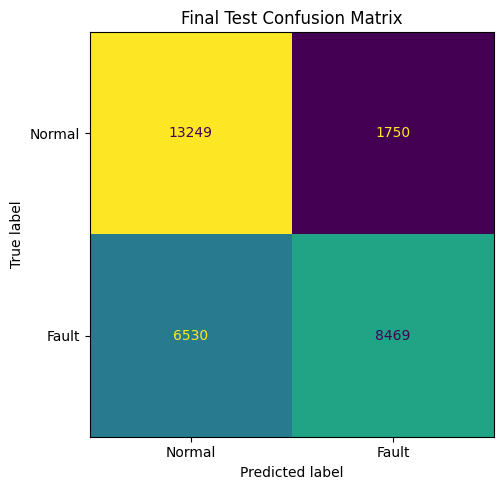


Performance by simulated fault type:


,fault_type,fault_detection_rate,examples,normal_specificity
0,dropout,0.5701,3743,NaN
1,noise,0.1771,3811,NaN
2,normal,NaN,14999,0.8833
3,spike,0.5292,3781,NaN
4,stuck_at,0.9986,3664,NaN



Saved files:
/content/pamap2_research/results/step10_final_test_results.csv
/content/pamap2_research/results/step10_test_confusion_matrix.png
/content/pamap2_research/results/step10_fault_type_test_results.csv

Test set used only for final evaluation: Yes


In [35]:

# STEP 10.1: FINAL HELD-OUT TEST EVALUATION
# Uses the selected model without retraining or tuning.
# Test participants were not used for model selection.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

assert "selected_xgb_model" in globals()
assert "test_df" in globals()

X_test = test_df[feature_cols]
y_test = test_df["fault_label"].astype(int)

# Final predictions on unseen participants.
test_pred = selected_xgb_model.predict(X_test)
test_prob = selected_xgb_model.predict_proba(X_test)[:, 1]

test_metrics = {
    "model": selected_xgb_name,
    "test_participants": ", ".join(
        map(str, sorted(test_df["participant_id"].unique()))
    ),
    "test_examples": len(test_df),
    "accuracy": accuracy_score(y_test, test_pred),
    "precision": precision_score(
        y_test, test_pred, zero_division=0
    ),
    "recall": recall_score(
        y_test, test_pred, zero_division=0
    ),
    "f1": f1_score(y_test, test_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, test_prob),
}

test_results_df = pd.DataFrame([test_metrics])

print("=" * 70)
print("STEP 10.1: FINAL TEST RESULTS")
print("=" * 70)
display(test_results_df.round(4))

print("\nClassification report:")
print(classification_report(
    y_test,
    test_pred,
    target_names=["Normal", "Simulated fault"],
    zero_division=0
))

# Save final binary metrics.
TEST_RESULTS_PATH = RESULTS_DIR / "step10_final_test_results.csv"
test_results_df.to_csv(TEST_RESULTS_PATH, index=False)

# Save confusion matrix figure.
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Fault"]
).plot(ax=ax, values_format="d", colorbar=False)
ax.set_title("Final Test Confusion Matrix")
fig.tight_layout()

CM_PATH = RESULTS_DIR / "step10_test_confusion_matrix.png"
fig.savefig(CM_PATH, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# Evaluate detection rate by simulated fault type.
test_detail = test_df[
    ["fault_type", "fault_label"]
].copy()
test_detail["prediction"] = test_pred

fault_type_rows = []
for fault_type, group in test_detail.groupby("fault_type"):
    if fault_type == "normal":
        # For normal examples, report the proportion correctly rejected.
        score = (group["prediction"] == 0).mean()
        metric_name = "normal_specificity"
    else:
        # For faulty examples, report the proportion detected as faulty.
        score = (group["prediction"] == 1).mean()
        metric_name = "fault_detection_rate"

    fault_type_rows.append({
        "fault_type": fault_type,
        metric_name: score,
        "examples": len(group),
    })

fault_type_results = pd.DataFrame(fault_type_rows)

FAULT_TYPE_RESULTS_PATH = (
    RESULTS_DIR / "step10_fault_type_test_results.csv"
)
fault_type_results.to_csv(FAULT_TYPE_RESULTS_PATH, index=False)

print("\nPerformance by simulated fault type:")
display(fault_type_results.round(4))

print("\nSaved files:")
print(TEST_RESULTS_PATH)
print(CM_PATH)
print(FAULT_TYPE_RESULTS_PATH)
print("\nTest set used only for final evaluation: Yes")


In [36]:
# STEP 10.2: CONSOLIDATE COMPLETED EXPERIMENT RESULTS
# Reuses existing result files; does not retrain models.

from pathlib import Path
import pandas as pd

RESULTS_DIR = Path("/content/pamap2_research/results")

result_files = [
    "step6_baseline_results.csv",
    "step7_xgboost_tuning.csv",
    "step8_motion_ablation.csv",
    "step9_efficiency_results.csv",
    "step10_final_test_results.csv",
    "step10_fault_type_test_results.csv",
]

summary_rows = []

for filename in result_files:
    path = RESULTS_DIR / filename

    if path.exists():
        df = pd.read_csv(path)
        summary_rows.append({
            "result_file": filename,
            "rows": len(df),
            "columns": ", ".join(df.columns.astype(str)),
            "status": "Available"
        })
    else:
        summary_rows.append({
            "result_file": filename,
            "rows": 0,
            "columns": "",
            "status": "Missing"
        })

results_inventory = pd.DataFrame(summary_rows)

display(results_inventory)

inventory_path = RESULTS_DIR / "step10_results_inventory.csv"
results_inventory.to_csv(inventory_path, index=False)

print(f"\nSaved: {inventory_path}")
print("No models were retrained and no original data was modified.")

,result_file,rows,columns,status
0,step6_baseline_results.csv,3,"model, accuracy, precision, recall, f1, roc_au...",Available
1,step7_xgboost_tuning.csv,4,"n_estimators, max_depth, learning_rate, accura...",Available
2,step8_motion_ablation.csv,2,"feature_set, feature_count, accuracy, precisio...",Available
3,step9_efficiency_results.csv,1,"model, feature_count, single_window_latency_ms...",Available
4,step10_final_test_results.csv,1,"model, test_participants, test_examples, accur...",Available
5,step10_fault_type_test_results.csv,5,"fault_type, fault_detection_rate, examples, no...",Available



Saved: /content/pamap2_research/results/step10_results_inventory.csv
No models were retrained and no original data was modified.
